In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [85]:
df = pd.read_csv("C:\\Users\\ASUS\\Downloads\\21015299-upi_transactions_2024\\upi_transactions 2024.csv")

## Problem Statement 1 — Data Quality & Reliability

In [86]:
df.head()

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


In [87]:
df.shape

(250000, 17)

In [88]:
df.columns

Index(['transaction id', 'timestamp', 'transaction type', 'merchant_category',
       'amount (INR)', 'transaction_status', 'sender_age_group',
       'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank',
       'device_type', 'network_type', 'fraud_flag', 'hour_of_day',
       'day_of_week', 'is_weekend'],
      dtype='object')

In [89]:
df.dtypes

transaction id        object
timestamp             object
transaction type      object
merchant_category     object
amount (INR)           int64
transaction_status    object
sender_age_group      object
receiver_age_group    object
sender_state          object
sender_bank           object
receiver_bank         object
device_type           object
network_type          object
fraud_flag             int64
hour_of_day            int64
day_of_week           object
is_weekend             int64
dtype: object

In [90]:
df["timestamp"] = pd.to_datetime(df["timestamp"])


In [91]:
df["timestamp"].dtype

dtype('<M8[ns]')

In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   transaction id      250000 non-null  object        
 1   timestamp           250000 non-null  datetime64[ns]
 2   transaction type    250000 non-null  object        
 3   merchant_category   250000 non-null  object        
 4   amount (INR)        250000 non-null  int64         
 5   transaction_status  250000 non-null  object        
 6   sender_age_group    250000 non-null  object        
 7   receiver_age_group  250000 non-null  object        
 8   sender_state        250000 non-null  object        
 9   sender_bank         250000 non-null  object        
 10  receiver_bank       250000 non-null  object        
 11  device_type         250000 non-null  object        
 12  network_type        250000 non-null  object        
 13  fraud_flag          250000 no

In [93]:
df.isnull().sum()

transaction id        0
timestamp             0
transaction type      0
merchant_category     0
amount (INR)          0
transaction_status    0
sender_age_group      0
receiver_age_group    0
sender_state          0
sender_bank           0
receiver_bank         0
device_type           0
network_type          0
fraud_flag            0
hour_of_day           0
day_of_week           0
is_weekend            0
dtype: int64

In [95]:
df.duplicated().sum()

np.int64(0)

In [96]:

df["transaction id"].duplicated().sum()

np.int64(0)

In [97]:
print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate transaction IDs:",
    df["transaction id"].duplicated().sum()
)

Exact duplicate rows: 0
Duplicate transaction IDs: 0


## Problem Statement 2 — Define the Fraud Lens and Prove the Accuracy Trap

In [98]:
df["fraud_flag"].value_counts()

fraud_flag
0    249520
1       480
Name: count, dtype: int64

In [99]:
fraud_percentage = df["fraud_flag"].value_counts(normalize=True) * 100

print("Genuine transactions:", round(fraud_percentage[0], 4), "%")
print("Fraudulent transactions:", round(fraud_percentage[1], 4), "%")

Genuine transactions: 99.808 %
Fraudulent transactions: 0.192 %


In [100]:
memory_usage = df.memory_usage(deep=True)

print("Memory used by each column:")
display(memory_usage)

print("\nTotal memory usage:")
print(round(memory_usage.sum() / (1024 ** 2), 2), "MB")

Memory used by each column:


Index                      128
transaction id        17500000
timestamp              2000000
transaction type      15398947
merchant_category     16051324
amount (INR)           2000000
transaction_status    15987624
sender_age_group      15474982
receiver_age_group    15474898
sender_state          16721093
sender_bank           15412294
receiver_bank         15413282
device_type           15751108
network_type          14800268
fraud_flag             2000000
hour_of_day            2000000
day_of_week           16034172
is_weekend             2000000
dtype: int64


Total memory usage:
190.75 MB


In [101]:
categorical_columns = [
    "transaction type",
    "merchant_category",
    "transaction_status",
    "sender_age_group",
    "receiver_age_group",
    "sender_state",
    "sender_bank",
    "receiver_bank",
    "device_type",
    "network_type",
    "day_of_week"
]

for col in categorical_columns:
    print(f"{col}: {df[col].nunique()} unique categories")
    

transaction type: 4 unique categories
merchant_category: 10 unique categories
transaction_status: 2 unique categories
sender_age_group: 5 unique categories
receiver_age_group: 5 unique categories
sender_state: 10 unique categories
sender_bank: 8 unique categories
receiver_bank: 8 unique categories
device_type: 3 unique categories
network_type: 4 unique categories
day_of_week: 7 unique categories


In [102]:
for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).to_string())


transaction type
transaction type
P2P             112445
P2M              87660
Bill Payment     37368
Recharge         12527

merchant_category
merchant_category
Grocery          49966
Food             37464
Shopping         29872
Fuel             25063
Other            24828
Utilities        22338
Transport        20105
Entertainment    20103
Healthcare       12663
Education         7598

transaction_status
transaction_status
SUCCESS    237624
FAILED      12376

sender_age_group
sender_age_group
26-35    87432
36-45    62873
18-25    62345
46-55    24841
56+      12509

receiver_age_group
receiver_age_group
26-35    87864
18-25    62611
36-45    62151
46-55    24823
56+      12551

sender_state
sender_state
Maharashtra       37427
Uttar Pradesh     30125
Karnataka         29756
Tamil Nadu        25367
Delhi             24870
Telangana         22435
Gujarat           20061
Andhra Pradesh    20006
Rajasthan         19981
West Bengal       19972

sender_bank
sender_bank
SBI         626

In [103]:
for col in categorical_columns:
    values = df[col].dropna().astype(str)
    spaces = values[values != values.str.strip()]

    if len(spaces) > 0:
        print(f"{col}: {len(spaces)} values contain extra spaces")
        print(spaces.unique())
    else:
        print(f"{col}: No leading or trailing spaces")

transaction type: No leading or trailing spaces
merchant_category: No leading or trailing spaces
transaction_status: No leading or trailing spaces
sender_age_group: No leading or trailing spaces
receiver_age_group: No leading or trailing spaces
sender_state: No leading or trailing spaces
sender_bank: No leading or trailing spaces
receiver_bank: No leading or trailing spaces
device_type: No leading or trailing spaces
network_type: No leading or trailing spaces
day_of_week: No leading or trailing spaces


In [104]:
for col in categorical_columns:
    values = df[col].dropna().astype(str)

    case_check = (
        pd.DataFrame({
            "original": values,
            "lowercase": values.str.lower()
        })
        .groupby("lowercase")["original"]
        .nunique()
    )

    inconsistent = case_check[case_check > 1]

    if len(inconsistent) > 0:
        print(f"\n{col}: Possible capitalisation inconsistencies")
        print(inconsistent)
    else:
        print(f"{col}: No capitalisation inconsistencies")

transaction type: No capitalisation inconsistencies
merchant_category: No capitalisation inconsistencies
transaction_status: No capitalisation inconsistencies
sender_age_group: No capitalisation inconsistencies
receiver_age_group: No capitalisation inconsistencies
sender_state: No capitalisation inconsistencies
sender_bank: No capitalisation inconsistencies
receiver_bank: No capitalisation inconsistencies
device_type: No capitalisation inconsistencies
network_type: No capitalisation inconsistencies
day_of_week: No capitalisation inconsistencies


transaction_id: retain for transaction tracking, exclude from model features.



fraud_flag: target variable, never a model input.



transaction_status: keep out of the initial feature set because its availability at the decision moment has not been established.



timestamp: use to derive decision-time features and to create chronological splits.



Balance columns: do not use them as fraud features, as required by your rules. The current CSV schema we audited does not contain balance columns.



No sender or receiver account IDs are present, so account-level behaviour cannot be directly analysed.

In [105]:
# Overall transaction statistics
total_transactions = len(df)
total_value = df["amount (INR)"].sum()


In [106]:
# Fraud and genuine transaction counts
fraud_count = (df["fraud_flag"] == 1).sum()
genuine_count = (df["fraud_flag"] == 0).sum()


In [107]:
# Transaction values by class
fraud_value = df.loc[df["fraud_flag"] == 1, "amount (INR)"].sum()
genuine_value = df.loc[df["fraud_flag"] == 0, "amount (INR)"].sum()


In [108]:
# Display results
print("OVERALL TRANSACTION OVERVIEW")
print("----------------------------")
print(f"Total transactions: {total_transactions:,}")
print(f"Total transaction value: ₹{total_value:,.2f}")


OVERALL TRANSACTION OVERVIEW
----------------------------
Total transactions: 250,000
Total transaction value: ₹327,939,009.00


## Problem Statement 3 — Diagnose Fraud Patterns (EDA)

In [109]:
print("\nFRAUD OVERVIEW")
print("--------------")
print(f"Fraud transactions: {fraud_count:,}")
print(f"Fraud transaction rate: {(fraud_count / total_transactions) * 100:.4f}%")
print(f"Fraud-labelled transaction value: ₹{fraud_value:,.2f}")


FRAUD OVERVIEW
--------------
Fraud transactions: 480
Fraud transaction rate: 0.1920%
Fraud-labelled transaction value: ₹719,631.00


In [110]:
print("\nGENUINE TRANSACTION OVERVIEW")
print("----------------------------")
print(f"Genuine transactions: {genuine_count:,}")
print(f"Genuine transaction rate: {(genuine_count / total_transactions) * 100:.4f}%")
print(f"Genuine transaction value: ₹{genuine_value:,.2f}")


GENUINE TRANSACTION OVERVIEW
----------------------------
Genuine transactions: 249,520
Genuine transaction rate: 99.8080%
Genuine transaction value: ₹327,219,378.00


In [111]:
amount_by_fraud = df.groupby("fraud_flag")["amount (INR)"].agg(
    ["count", "mean", "median", "min", "max", "sum"]
)

amount_by_fraud.index = ["Genuine (0)", "Fraud (1)"]

print(amount_by_fraud)

              count         mean  median  min    max        sum
Genuine (0)  249520  1311.395391   629.0   10  42099  327219378
Fraud (1)       480  1499.231250   618.5   28  17718     719631


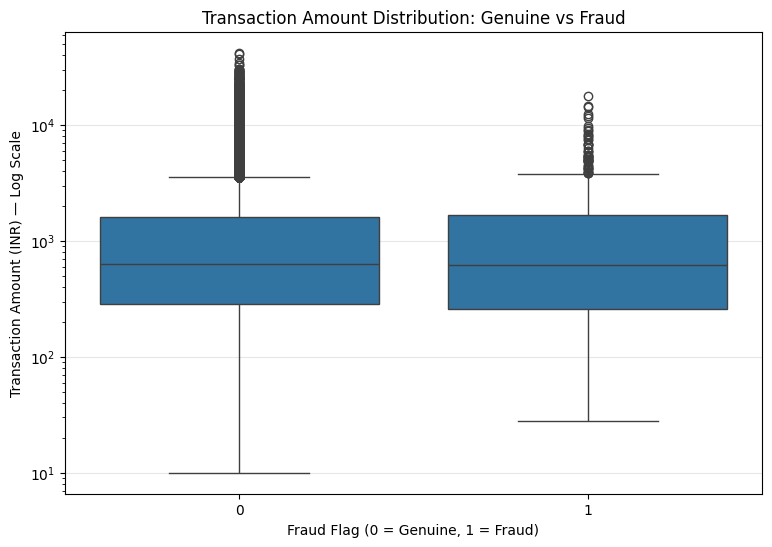

In [112]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="fraud_flag",
    y="amount (INR)"
)

plt.yscale("log")
plt.xlabel("Fraud Flag (0 = Genuine, 1 = Fraud)")
plt.ylabel("Transaction Amount (INR) — Log Scale")
plt.title("Transaction Amount Distribution: Genuine vs Fraud")
plt.grid(axis="y", alpha=0.3)

plt.show()

Transaction amount distributions for genuine and fraud-labelled transactions show substantial overlap. Fraud-labelled transactions have a higher mean amount (₹1,499.23) but a slightly lower median amount (₹618.50) than genuine transactions (mean ₹1,311.40; median ₹629). Both classes contain high-value outliers. Therefore, transaction amount alone may not provide sufficient separation for reliable fraud detection.

In [113]:
type_analysis = df.groupby("transaction type").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum"),
    total_amount=("amount (INR)", "sum"),
    fraud_amount=("amount (INR)", lambda x: x[df.loc[x.index, "fraud_flag"] == 1].sum())
)

type_analysis["fraud_rate_percent"] = (
    type_analysis["fraud_transactions"]
    / type_analysis["total_transactions"] * 100
)

type_analysis["average_amount"] = (
    type_analysis["total_amount"]
    / type_analysis["total_transactions"]
)

print(type_analysis.sort_values("fraud_rate_percent", ascending=False).round(2))

                  total_transactions  fraud_transactions  total_amount  \
transaction type                                                         
Recharge                       12527                  30      16171051   
Bill Payment                   37368                  77      48895743   
P2M                            87660                 167     115717567   
P2P                           112445                 206     147154648   

                  fraud_amount  fraud_rate_percent  average_amount  
transaction type                                                    
Recharge                 30611                0.24         1290.90  
Bill Payment            105837                0.21         1308.49  
P2M                     312297                0.19         1320.07  
P2P                     270886                0.18         1308.68  


1. Recharge has the highest observed fraud rate.

Recharge has a fraud rate of 0.24%, compared with the overall rate of 0.192%.

2. P2P has the most fraud cases.

P2P accounts for 206 of the 480 fraud-labelled transactions, despite having the lowest fraud rate among the four types.

This is why we must examine both fraud counts and fraud rates.

3. Average transaction amounts are similar.

All four types have average amounts between approximately ₹1,291 and ₹1,320. Transaction type differences in fraud rate are therefore not simply reflected in large differences in average transaction amount.

4. These are descriptive findings, not causal explanations.

We cannot conclude that Recharge is inherently riskier. We need to examine the number of observations, uncertainty and other transaction characteristics before recommending different treatment.
Record this finding
Recharge transactions have the highest observed fraud rate (0.24%), followed by Bill Payment (0.21%), P2M (0.19%) and P2P (0.18%). However, P2P contributes the largest number of fraud-labelled transactions (206 of 480). This demonstrates why fraud rates and absolute fraud counts should be considered together.

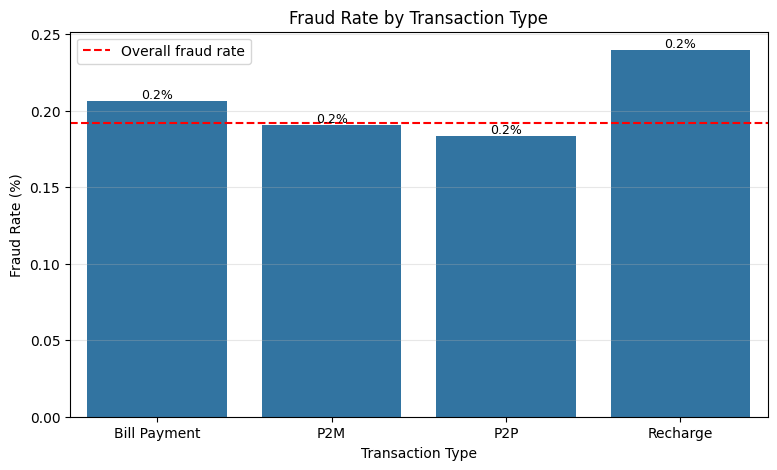

In [114]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=type_analysis.reset_index(),
    x="transaction type",
    y="fraud_rate_percent"
)

# Add overall fraud rate line
plt.axhline(
    y=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Transaction Type")
plt.legend()
plt.grid(axis="y", alpha=0.3)

# Add labels on bars
ax = plt.gca()
for p in ax.patches:
    value = p.get_height()
    if not np.isnan(value):  # avoid NaN issues
        ax.annotate(
            f'{value:.1f}%',  # format with one decimal
            (p.get_x() + p.get_width() / 2., value),
            ha='center', va='bottom',
            fontsize=9, color='black'
        )

plt.show()



In [115]:
merchant_analysis = df.groupby("merchant_category").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum"),
    total_amount=("amount (INR)", "sum"),
    fraud_amount=("amount (INR)", lambda x: x[df.loc[x.index, "fraud_flag"] == 1].sum())
)

merchant_analysis["fraud_rate_percent"] = (
    merchant_analysis["fraud_transactions"]
    / merchant_analysis["total_transactions"] * 100
)

merchant_analysis["average_amount"] = (
    merchant_analysis["total_amount"]
    / merchant_analysis["total_transactions"]
)

print(
    merchant_analysis
    .sort_values("fraud_rate_percent", ascending=False)
    .round(3)
)

                   total_transactions  fraud_transactions  total_amount  \
merchant_category                                                         
Transport                       20105                  43       6192416   
Education                        7598                  16      38704346   
Shopping                        29872                  62      76863207   
Other                           24828                  50      21073449   
Entertainment                   20103                  40       8309080   
Food                            37464                  73      19919402   
Fuel                            25063                  48      38982575   
Grocery                         49966                  94      58277893   
Healthcare                      12663                  21       6874159   
Utilities                       22338                  33      52742482   

                   fraud_amount  fraud_rate_percent  average_amount  
merchant_category            

Four observations
1. Transport has the highest fraud rate.

Transport has a 0.214% fraud rate, followed closely by Education (0.211%) and Shopping (0.208%).

2. Grocery has the largest fraud count.

Grocery has 94 fraud-labelled transactions, the highest among all merchant categories. However, its fraud rate is 0.188%, below the overall rate of 0.192%.

3. Utilities has the lowest observed fraud rate.

Utilities has a 0.148% rate, while Healthcare has 0.166%.

4. Average transaction amounts vary considerably.

Education has an average transaction amount of ₹5,094, while Entertainment averages ₹413. This tells us merchant categories have very different transaction-value profiles.
Important limitation
Education's high average amount does not mean Education transactions are more fraudulent. Similarly, Transport's higher fraud rate does not establish that the category causes fraud. These are descriptive associations, and some categories have relatively few fraud cases.

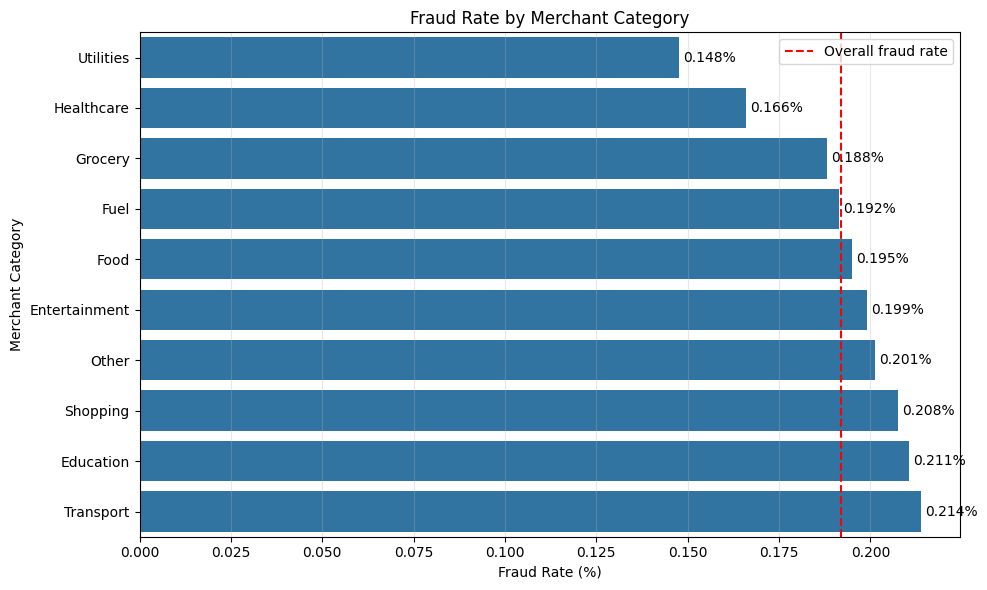

In [116]:
merchant_plot = merchant_analysis.sort_values(
    "fraud_rate_percent",
    ascending=True
).reset_index()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=merchant_plot,
    x="fraud_rate_percent",
    y="merchant_category"
)

ax.axvline(
    x=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f%%",
    padding=3
)

plt.xlabel("Fraud Rate (%)")
plt.ylabel("Merchant Category")
plt.title("Fraud Rate by Merchant Category")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [117]:
type_merchant_analysis = df.pivot_table(
    index="transaction type",
    columns="merchant_category",
    values="fraud_flag",
    aggfunc="mean"
) * 100

print(type_merchant_analysis.round(3))

merchant_category  Education  Entertainment   Food   Fuel  Grocery  \
transaction type                                                     
Bill Payment           0.376          0.170  0.160  0.191    0.214   
P2M                    0.185          0.129  0.213  0.200    0.196   
P2P                    0.173          0.241  0.202  0.189    0.173   
Recharge               0.277          0.389  0.107  0.157    0.195   

merchant_category  Healthcare  Other  Shopping  Transport  Utilities  
transaction type                                                      
Bill Payment            0.264  0.262     0.243      0.163      0.152  
P2M                     0.113  0.150     0.268      0.241      0.127  
P2P                     0.123  0.224     0.127      0.200      0.169  
Recharge                0.597  0.168     0.410      0.302      0.090  


In [118]:
type_merchant_counts = pd.crosstab(
    df["transaction type"],
    df["merchant_category"]
)

print(type_merchant_counts)

merchant_category  Education  Entertainment   Food   Fuel  Grocery  \
transaction type                                                     
Bill Payment            1063           2948   5611   3672     7471   
P2M                     2705           6989  13132   9005    17345   
P2P                     3469           9137  16848  11116    22580   
Recharge                 361           1029   1873   1270     2570   

merchant_category  Healthcare  Other  Shopping  Transport  Utilities  
transaction type                                                      
Bill Payment             1893   3815      4525       3071       3299  
P2M                      4429   8682     10451       7041       7881  
P2P                      5671  11143     13434       9000      10047  
Recharge                  670   1188      1462        993       1111  


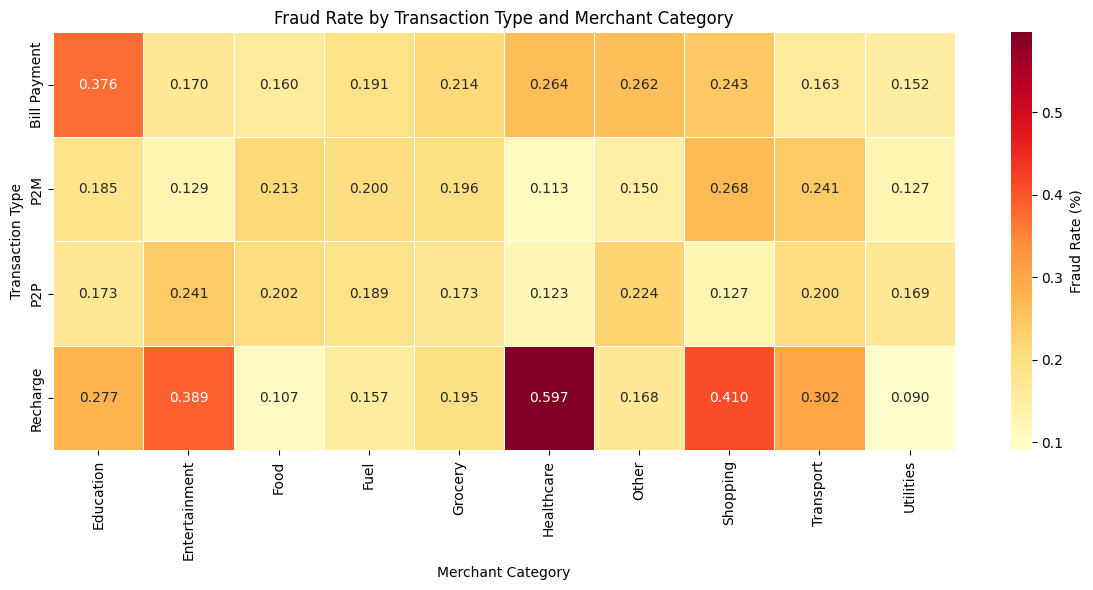

In [119]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    type_merchant_analysis,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Fraud Rate (%)"}
)

plt.title("Fraud Rate by Transaction Type and Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Transaction Type")

plt.tight_layout()
plt.show()

In [120]:
hour_analysis = df.groupby("hour_of_day").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

hour_analysis["fraud_rate_percent"] = (
    hour_analysis["fraud_transactions"]
    / hour_analysis["total_transactions"] * 100
)

print(hour_analysis.round(3))

             total_transactions  fraud_transactions  fraud_rate_percent
hour_of_day                                                            
0                          3388                   8               0.236
1                          2244                   6               0.267
2                          1685                   3               0.178
3                          1314                   4               0.304
4                          1247                   1               0.080
5                          1742                   1               0.057
6                          3501                   5               0.143
7                          5630                  13               0.231
8                          8349                  18               0.216
9                         10450                  20               0.191
10                        13904                  20               0.144
11                        16328                  27             

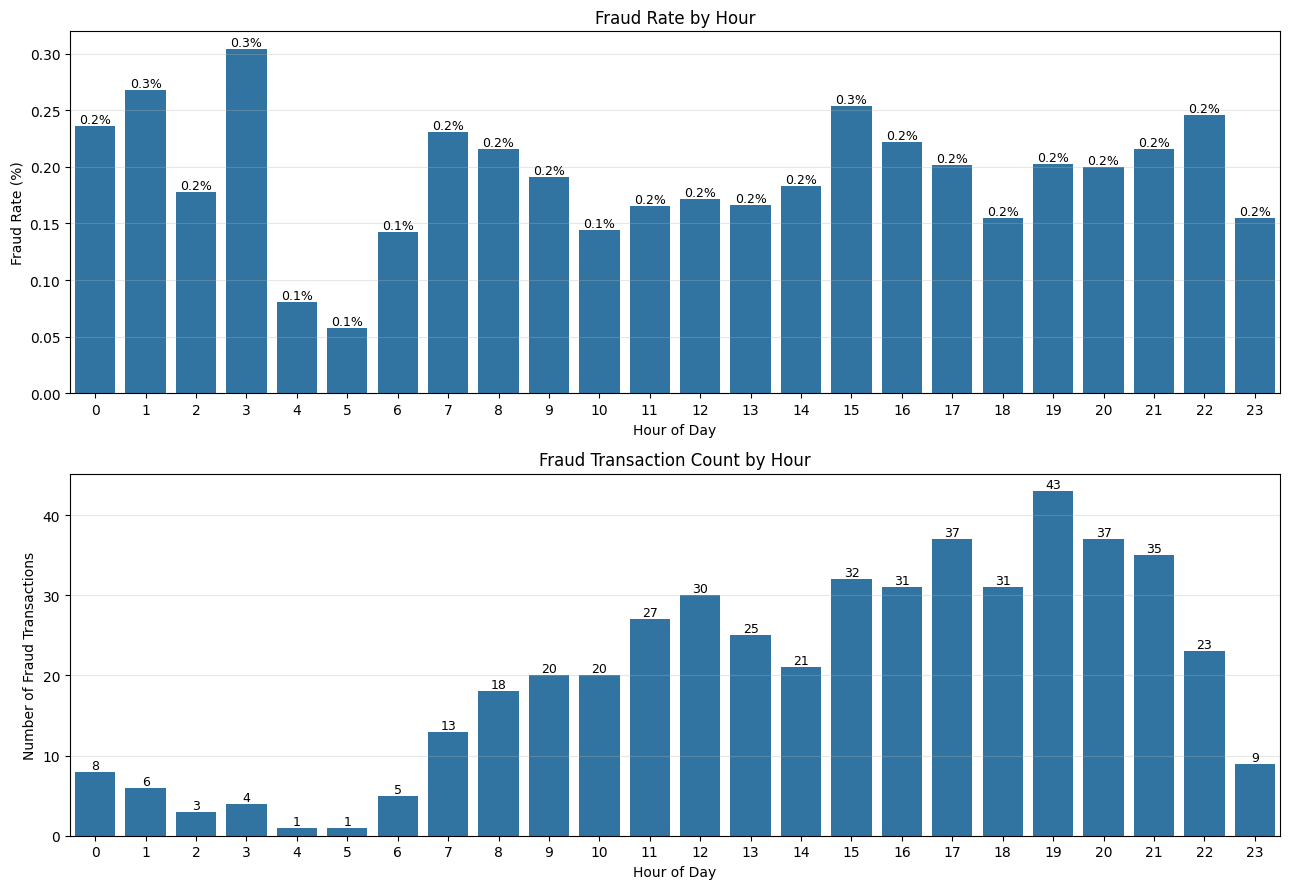

In [121]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Chart 1: Fraud rate by hour
sns.barplot(
    x=hour_analysis.index,
    y=hour_analysis["fraud_rate_percent"],
    ax=axes[0]
)
axes[0].set_title("Fraud Rate by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Fraud Rate (%)")
axes[0].grid(axis="y", alpha=0.3)

# Add labels for fraud rate
for p in axes[0].patches:
    value = p.get_height()
    if not np.isnan(value):
        axes[0].annotate(
            f'{value:.1f}%',
            (p.get_x() + p.get_width() / 2., value),
            ha='center', va='bottom',
            fontsize=9, color='black'
        )

# Chart 2: Fraud count by hour
sns.barplot(
    x=hour_analysis.index,
    y=hour_analysis["fraud_transactions"],
    ax=axes[1]
)
axes[1].set_title("Fraud Transaction Count by Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Number of Fraud Transactions")
axes[1].grid(axis="y", alpha=0.3)

# Add labels for fraud count
for p in axes[1].patches:
    value = p.get_height()
    if not np.isnan(value):
        axes[1].annotate(
            f'{int(value)}',
            (p.get_x() + p.get_width() / 2., value),
            ha='center', va='bottom',
            fontsize=9, color='black'
        )

plt.tight_layout()
plt.show()


In [122]:
day_analysis = df.groupby("day_of_week").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

day_analysis["fraud_rate_percent"] = (
    day_analysis["fraud_transactions"]
    / day_analysis["total_transactions"] * 100
)

# Arrange days in calendar order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_analysis = day_analysis.reindex(day_order)

print(day_analysis.round(3))

             total_transactions  fraud_transactions  fraud_rate_percent
day_of_week                                                            
Monday                    36495                  71               0.195
Tuesday                   35540                  58               0.163
Wednesday                 35700                  75               0.210
Thursday                  35432                  72               0.203
Friday                    35496                  61               0.172
Saturday                  35334                  68               0.192
Sunday                    36003                  75               0.208


Important interpretation
Unlike the hourly analysis, transaction volumes are relatively balanced across weekdays. This makes the daily fraud-rate comparison easier to interpret.

However, the difference between Wednesday (0.210%) and Tuesday (0.163%) is still small in absolute terms. We should not create weekday-specific blocking rules from this observation alone.

Finding to record:
Wednesday (0.210%) and Sunday (0.208%) have the highest observed fraud rates, while Tuesday has the lowest (0.163%). Transaction volumes are relatively consistent across days. Day of week may provide contextual information, but the observed differences require further validation before being used in risk decisions

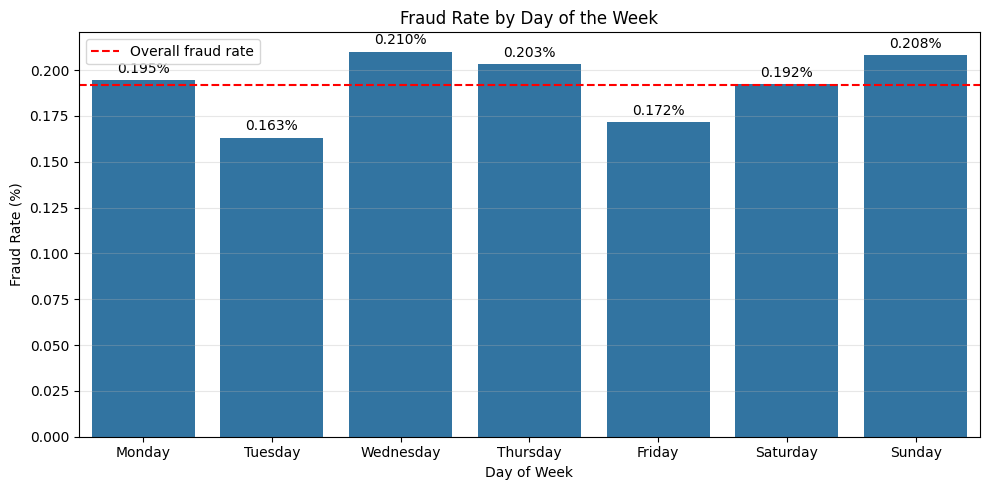

In [123]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=day_analysis.index,
    y=day_analysis["fraud_rate_percent"]
)

ax.axhline(
    y=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f%%",
    padding=3
)

plt.xlabel("Day of Week")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Day of the Week")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


Chart validated
- Wednesday (0.210%) and Sunday (0.208%) are above the overall fraud rate.
- Thursday (0.203%) and Monday (0.195%) are also slightly above or close to it.
- Saturday (0.192%) is almost exactly equal to the overall rate.
- Tuesday (0.163%) and Friday (0.172%) are below it.
Conclusion: Day-of-week differences exist, but they are modest. We should retain day of week as a candidate contextual feature rather than create separate blocking rules for particular days.

In [124]:
weekend_analysis = df.groupby("is_weekend").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

weekend_analysis["fraud_rate_percent"] = (
    weekend_analysis["fraud_transactions"]
    / weekend_analysis["total_transactions"] * 100
)

weekend_analysis.index = ["Weekday" if x == 0 else "Weekend"
                          for x in weekend_analysis.index]

print(weekend_analysis.round(3))

         total_transactions  fraud_transactions  fraud_rate_percent
Weekday              178663                 337               0.189
Weekend               71337                 143               0.200


What do we observe?
1. Weekend fraud rate is 0.200%, compared with 0.189% on weekdays.
2. The weekend rate is approximately 5.8% higher relative to the weekday rate.
3. Weekdays account for more fraud cases (337), mainly because they have considerably more transactions.
4. The difference in fraud rates is only 0.011 percentage points.
Important: This is a small observed difference. We should not conclude that weekends are meaningfully riskier without statistical testing and validation on unseen data.
Record this finding
Weekend transactions have a slightly higher observed fraud rate (0.200%) than weekday transactions (0.189%). However, weekdays contribute more fraud-labelled transactions (337 versus 143) due to their higher transaction volume. The difference is modest and should be validated before influencing payment decisions.

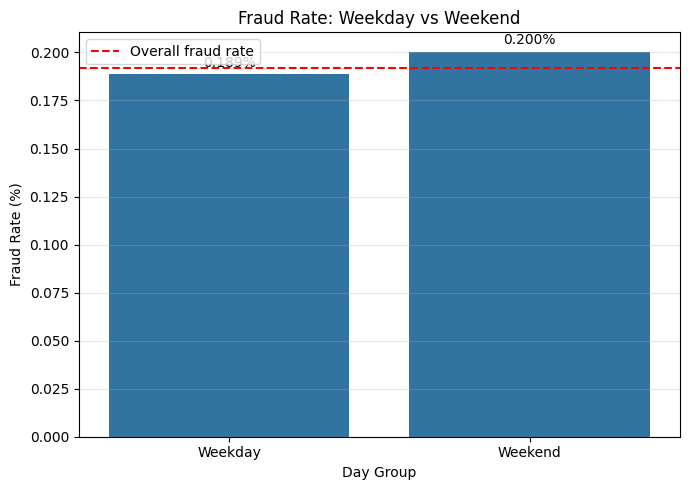

In [125]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=weekend_analysis.index,
    y=weekend_analysis["fraud_rate_percent"]
)

ax.axhline(
    y=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f%%",
    padding=3
)

plt.xlabel("Day Group")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate: Weekday vs Weekend")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [126]:
df["month"] = df["timestamp"].dt.month

monthly_analysis = df.groupby("month").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

monthly_analysis["fraud_rate_percent"] = (
    monthly_analysis["fraud_transactions"]
    / monthly_analysis["total_transactions"] * 100
)

print(monthly_analysis.round(3))

       total_transactions  fraud_transactions  fraud_rate_percent
month                                                            
1                   21221                  50               0.236
2                   19759                  34               0.172
3                   21234                  47               0.221
4                   20536                  33               0.161
5                   21333                  37               0.173
6                   20628                  30               0.145
7                   21207                  52               0.245
8                   21231                  33               0.155
9                   20597                  42               0.204
10                  21252                  45               0.212
11                  20366                  39               0.191
12                  20636                  38               0.184


Four observations
1. July has the highest fraud rate.

July records 52 fraud cases and a 0.245% fraud rate.

2. June has the lowest fraud rate.

June records 30 fraud cases and a 0.145% fraud rate.

3. January also has a relatively high rate.

January has 50 fraud cases and a 0.236% rate.

4. Transaction volumes are relatively consistent.

Monthly transaction counts range from 19,759 to 21,333. Therefore, differences in fraud rates are not simply explained by major differences in monthly transaction volumes.
What does this mean for our project?
We have observed monthly variation, but we cannot yet call this fraud seasonality or prove a changing fraud trend. We need to validate the pattern statistically and evaluate how well models perform on later periods.
Record this finding
Monthly fraud rates vary during 2024, ranging from 0.145% in June to 0.245% in July. July has the highest fraud count (52), while June has the lowest (30). Monthly transaction volumes remain relatively stable. These observations suggest possible temporal variation that should be considered during chronological model validation.

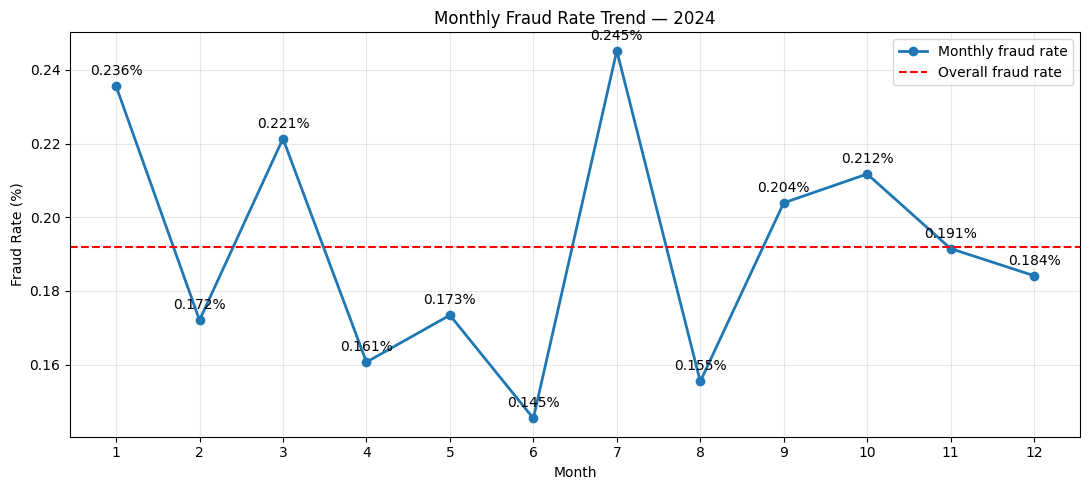

In [127]:
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_analysis.index,
    monthly_analysis["fraud_rate_percent"],
    marker="o",
    linewidth=2,
    label="Monthly fraud rate"
)

plt.axhline(
    y=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

for month, rate in monthly_analysis["fraud_rate_percent"].items():
    plt.annotate(
        f"{rate:.3f}%",
        (month, rate),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Fraud Rate (%)")
plt.title("Monthly Fraud Rate Trend — 2024")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

Important modelling implication
This variation makes chronological validation particularly important. We should train on earlier transactions, validate on later transactions, and reserve the latest period for final testing.

We should not randomly shuffle transactions into train and test sets because that could hide changes over time.

Record this finding:
Monthly fraud rates fluctuate during 2024, with a peak of 0.245% in July and a low of 0.145% in June. No consistent upward or downward trend is evident. Chronological validation is therefore important for assessing model stability over time.

In [128]:
device_analysis = df.groupby("device_type").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

device_analysis["fraud_rate_percent"] = (
    device_analysis["fraud_transactions"]
    / device_analysis["total_transactions"] * 100
)

print(device_analysis.round(3))

             total_transactions  fraud_transactions  fraud_rate_percent
device_type                                                            
Android                  187777                 364               0.194
Web                       12610                  26               0.206
iOS                       49613                  90               0.181


What do we observe?
1. Web has the highest observed fraud rate: 0.206%.
2. Android has the highest fraud count: 364 of 480 fraud-labelled transactions.
3. iOS has the lowest observed fraud rate: 0.181%.
4. The differences are relatively small. Web's rate is only 0.012 percentage points above the overall rate of 0.192%.
Business interpretation
Device type may provide useful contextual information to the fraud detection model. However, we should not automatically treat Web transactions as suspicious or Android transactions as risky simply because Android accounts for more fraud cases.

Android has by far the largest transaction volume, which explains why it also has the largest fraud count.

Record this finding:
Web transactions have the highest observed fraud rate (0.206%), followed by Android (0.194%) and iOS (0.181%). Android contributes the largest number of fraud-labelled transactions (364) because it dominates transaction volume. Device type may be useful as a contextual model feature, but the observed differences do not justify device-based blocking rules.

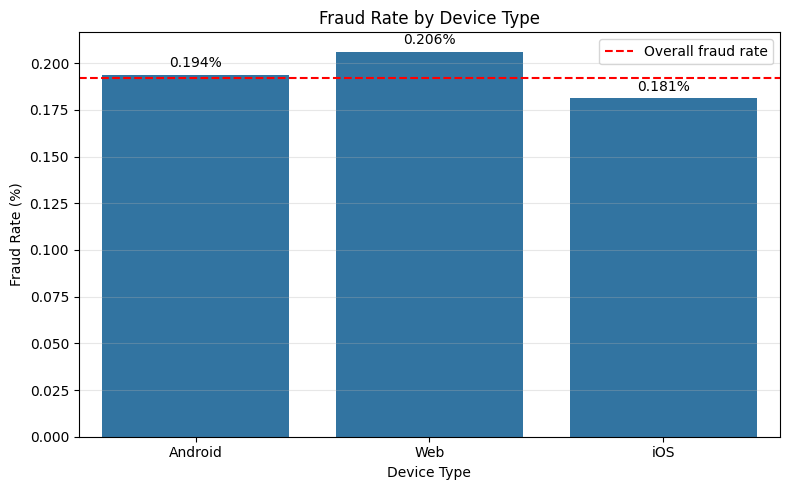

In [129]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=device_analysis.index,
    y=device_analysis["fraud_rate_percent"]
)

ax.axhline(
    y=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f%%",
    padding=3
)

plt.xlabel("Device Type")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Device Type")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [130]:
network_analysis = df.groupby("network_type").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

network_analysis["fraud_rate_percent"] = (
    network_analysis["fraud_transactions"]
    / network_analysis["total_transactions"] * 100
)

print(network_analysis.round(3))


              total_transactions  fraud_transactions  fraud_rate_percent
network_type                                                            
3G                         12471                  24               0.192
4G                        149813                 282               0.188
5G                         62582                 115               0.184
WiFi                       25134                  59               0.235


What do we observe?
1. WiFi has the highest observed fraud rate.

At 0.235%, WiFi is above the overall fraud rate of 0.192%.

2. 4G has the highest fraud count.

There are 282 fraud-labelled transactions on 4G. However, 4G also accounts for approximately 60% of all transactions.

3. 5G has the lowest observed fraud rate.

Its rate is 0.184%, slightly below the overall rate.

4. 3G is almost equal to the overall rate.

Both are approximately 0.192%.
Important interpretation
WiFi's higher observed rate makes it worth investigating, but it does not prove that WiFi connections cause fraud. We should also examine device-network combinations to see whether the observed difference is concentrated in particular devices.

Record this finding:
WiFi transactions have the highest observed fraud rate (0.235%), while 4G contributes the largest number of fraud-labelled transactions (282) because of its high transaction volume. Network type may provide useful contextual information, but these descriptive differences do not justify automatically blocking WiFi transactions

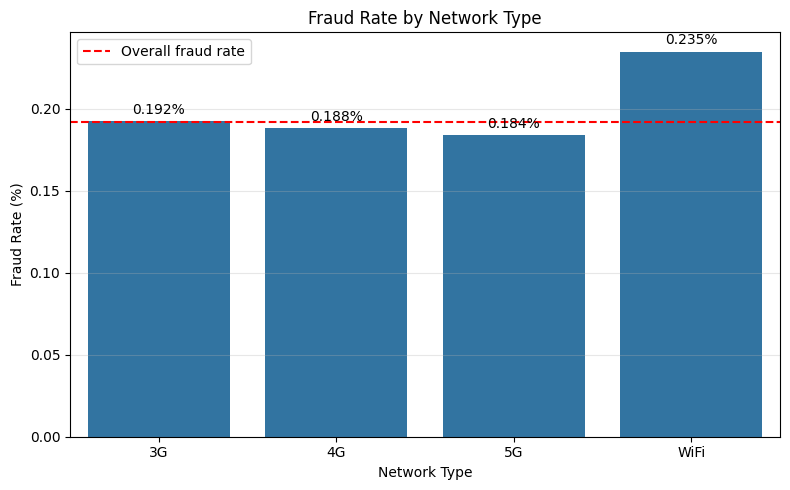

In [131]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=network_analysis.index,
    y=network_analysis["fraud_rate_percent"]
)

ax.axhline(
    y=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f%%",
    padding=3
)

plt.xlabel("Network Type")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Network Type")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [132]:
device_network_analysis = df.pivot_table(
    index="device_type",
    columns="network_type",
    values="fraud_flag",
    aggfunc="mean"
) * 100

device_network_counts = pd.crosstab(
    df["device_type"],
    df["network_type"]
)

print("FRAUD RATE (%)")
print(device_network_analysis.round(3))

print("\nTRANSACTION COUNTS")
print(device_network_counts)

FRAUD RATE (%)
network_type     3G     4G     5G   WiFi
device_type                             
Android       0.222  0.191  0.174  0.244
Web           0.000  0.226  0.221  0.155
iOS           0.125  0.167  0.210  0.221

TRANSACTION COUNTS
network_type    3G      4G     5G   WiFi
device_type                             
Android       9441  112413  47058  18865
Web            636    7519   3165   1290
iOS           2394   29881  12359   4979


Key observations
1. Android + WiFi: 0.244%, the highest rate among Android combinations.
2. iOS + WiFi: 0.221%, also relatively high.
3. Web + 4G: 0.226%, the highest rate among Web combinations.
4. Web + 3G: 0.000%, but this combination has only 636 transactions. Zero observed fraud cases does not mean zero future risk.
5. The WiFi rate is relatively high for Android and iOS, but not for Web.
Why this matters
The overall WiFi fraud rate is 0.235%, but that aggregate hides differences between devices. This is a good example of why contextual combinations may be more informative than examining individual columns independently.

However, these combinations have different transaction volumes. We must retain the counts alongside the rates, and the model must validate whether these patterns generalise to later transactions.

Record this finding:
Fraud rates differ across device-network combinations. Android-WiFi (0.244%) and iOS-WiFi (0.221%) show relatively high observed rates, while Web-4G has the highest rate among Web transactions (0.226%). Web-3G has no observed fraud cases among 636 transactions, which is insufficient evidence to conclude that the combination is safe. Device-network combinations may provide useful contextual features for modelling.

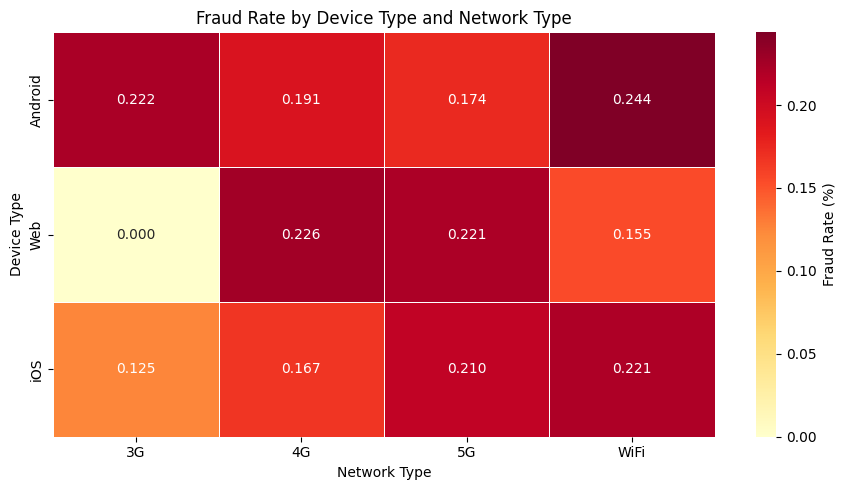

In [133]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    device_network_analysis,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Fraud Rate (%)"}
)

plt.title("Fraud Rate by Device Type and Network Type")
plt.xlabel("Network Type")
plt.ylabel("Device Type")
plt.tight_layout()

plt.show()

The main patterns are:
- Android + WiFi: 0.244% — highest observed combination.
- Web + 4G: 0.226% — highest Web combination.
- iOS + WiFi: 0.221%.
- Web + 3G: 0.000% — but only 636 transactions, so this should not be interpreted as zero risk.
One important improvement for the final presentation: show the transaction counts alongside this heatmap, perhaps as a small table. A rate based on 636 transactions has less supporting evidence than one based on 18,865 transactions.

Finding to retain: Device-network combinations reveal differences that are hidden when each variable is analysed independently. These combinations are candidates for contextual model features, subject to validation.

In [134]:
sender_bank_analysis = df.groupby("sender_bank").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

sender_bank_analysis["fraud_rate_percent"] = (
    sender_bank_analysis["fraud_transactions"]
    / sender_bank_analysis["total_transactions"] * 100
)

sender_bank_analysis = sender_bank_analysis.sort_values(
    "fraud_rate_percent",
    ascending=False
)

print(sender_bank_analysis.round(3))

             total_transactions  fraud_transactions  fraud_rate_percent
sender_bank                                                            
Kotak                     20032                  50               0.250
ICICI                     29769                  66               0.222
PNB                       24946                  52               0.208
IndusInd                  25173                  52               0.207
Axis                      25042                  49               0.196
SBI                       62693                 109               0.174
HDFC                      37485                  62               0.165
Yes Bank                  24860                  40               0.161


What do we observe?
1. Kotak has the highest observed fraud rate: 0.250%.
2. Yes Bank has the lowest: 0.161%.
3. SBI has the highest fraud count: 109 cases, but it also has the largest transaction volume.
4. Kotak's observed rate is higher than the overall rate of 0.192%.
5. The difference between Kotak and Yes Bank is 0.089 percentage points.
Important interpretation
Bank identity may provide contextual information, but these results do not establish that a particular bank causes or enables fraud. We also need to consider transaction volumes and validate any bank-related patterns on later, unseen data.

Finding to record:
Sender-bank fraud rates vary across the dataset. Kotak has the highest observed rate (0.250%), while Yes Bank has the lowest (0.161%). SBI contributes the largest number of fraud-labelled transactions (109) because it has the highest transaction volume. Sender bank may be a candidate model feature, but these associations should not be interpreted causally.

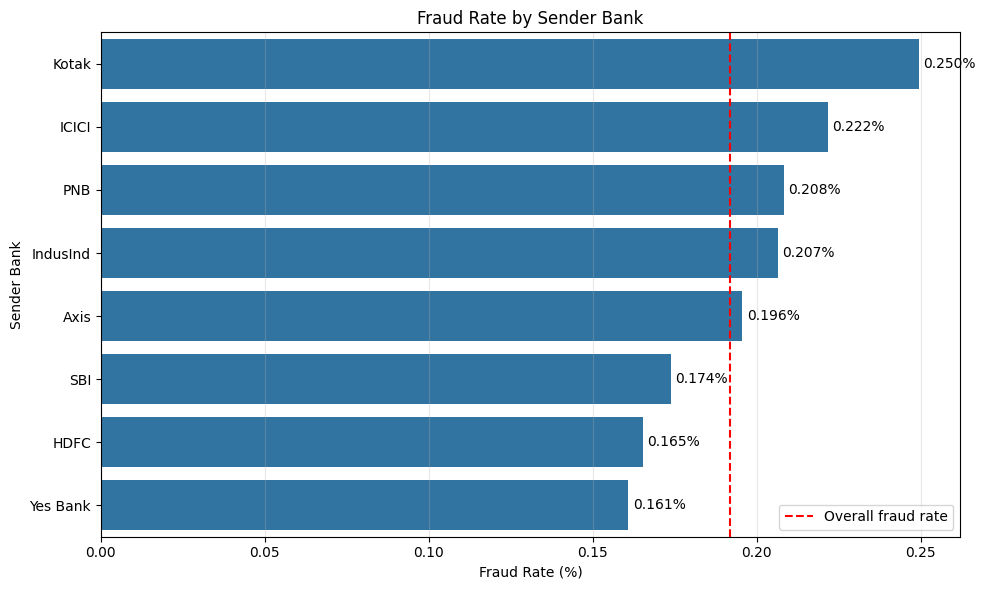

In [135]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=sender_bank_analysis.reset_index(),
    x="fraud_rate_percent",
    y="sender_bank"
)

ax.axvline(
    x=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f%%",
    padding=3
)

plt.xlabel("Fraud Rate (%)")
plt.ylabel("Sender Bank")
plt.title("Fraud Rate by Sender Bank")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [136]:
receiver_bank_analysis = df.groupby("receiver_bank").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

receiver_bank_analysis["fraud_rate_percent"] = (
    receiver_bank_analysis["fraud_transactions"]
    / receiver_bank_analysis["total_transactions"] * 100
)

receiver_bank_analysis = receiver_bank_analysis.sort_values(
    "fraud_rate_percent",
    ascending=False
)

print(receiver_bank_analysis.round(3))

               total_transactions  fraud_transactions  fraud_rate_percent
receiver_bank                                                            
IndusInd                    25086                  52               0.207
Yes Bank                    25009                  51               0.204
Kotak                       20138                  41               0.204
PNB                         24802                  49               0.198
HDFC                        37651                  73               0.194
ICICI                       29944                  57               0.190
SBI                         62378                 116               0.186
Axis                        24992                  41               0.164


What do we observe?
1. IndusInd has the highest observed receiver-bank fraud rate: 0.207%.
2. Axis has the lowest: 0.164%.
3. SBI has the highest fraud count: 116, but it also has the highest transaction volume.
4. The receiver-bank rates are relatively close together, ranging from 0.164% to 0.207%.
5. The overall fraud rate is 0.192%.
Compare sender and receiver results
An interesting observation is that:
- Kotak has the highest sender-bank fraud rate (0.250%), but its receiver-bank rate is 0.204%.
- IndusInd has the highest receiver-bank fraud rate (0.207%), but its sender-bank rate is 0.207%.
This suggests that sender and receiver bank roles may contain different contextual information.

Finding to record:
Receiver-bank fraud rates range from 0.164% for Axis to 0.207% for IndusInd. SBI contributes the highest number of fraud-labelled transactions (116), reflecting its high transaction volume. Sender and receiver bank patterns differ, so both roles may be worth evaluating as separate contextual model features. These are descriptive associations, not evidence of bank responsibility.

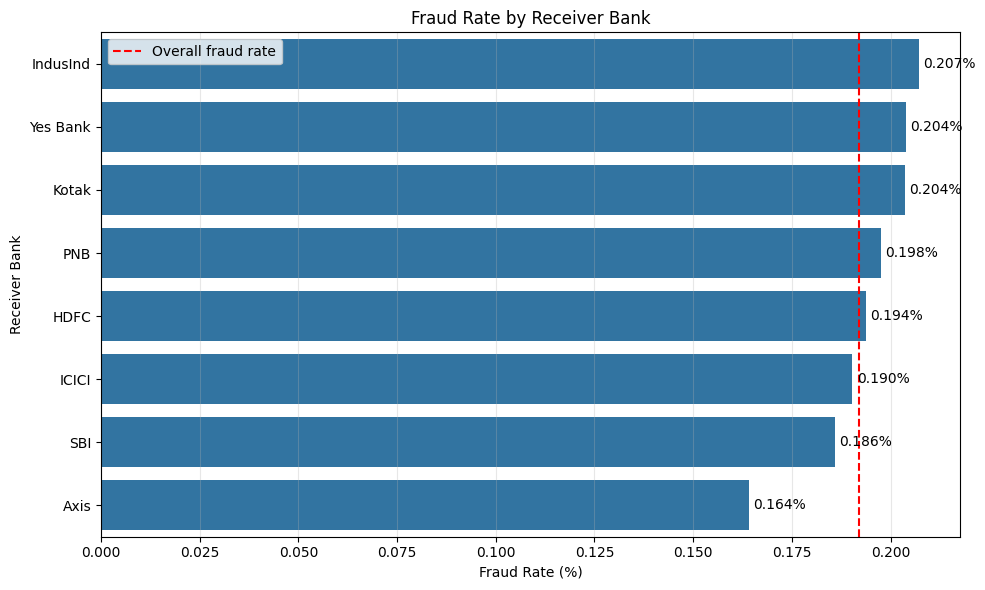

In [137]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=receiver_bank_analysis.reset_index(),
    x="fraud_rate_percent",
    y="receiver_bank"
)

ax.axvline(
    x=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f%%",
    padding=3
)

plt.xlabel("Fraud Rate (%)")
plt.ylabel("Receiver Bank")
plt.title("Fraud Rate by Receiver Bank")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [138]:
state_analysis = df.groupby("sender_state").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

state_analysis["fraud_rate_percent"] = (
    state_analysis["fraud_transactions"]
    / state_analysis["total_transactions"] * 100
)

state_analysis = state_analysis.sort_values(
    "fraud_rate_percent",
    ascending=False
)

print(state_analysis.round(3))

                total_transactions  fraud_transactions  fraud_rate_percent
sender_state                                                              
Karnataka                    29756                  69               0.232
Rajasthan                    19981                  46               0.230
Gujarat                      20061                  43               0.214
Delhi                        24870                  50               0.201
Maharashtra                  37427                  71               0.190
West Bengal                  19972                  35               0.175
Andhra Pradesh               20006                  35               0.175
Telangana                    22435                  39               0.174
Uttar Pradesh                30125                  52               0.173
Tamil Nadu                   25367                  40               0.158


What do we observe?
1. Karnataka has the highest observed fraud rate: 0.232%.
2. Rajasthan is very close: 0.230%.
3. Tamil Nadu has the lowest: 0.158%.
4. Maharashtra has the highest fraud count: 71 cases, with 37,427 transactions.
5. Karnataka and Rajasthan have higher observed rates despite having fewer transactions than Maharashtra.
Important interpretation
The difference between Karnataka (0.232%) and Tamil Nadu (0.158%) is 0.074 percentage points.

However, we must not interpret this as evidence that a state is inherently more dangerous or that its residents are more likely to commit fraud. State is only a recorded transaction attribute in this dataset. Its usefulness must be evaluated carefully, including whether it introduces unfair geographical bias.

Finding to record:
Sender-state fraud rates vary across the dataset. Karnataka (0.232%) and Rajasthan (0.230%) have the highest observed rates, while Tamil Nadu has the lowest (0.158%). Maharashtra contributes the largest number of fraud-labelled transactions (71). These are dataset-level associations and require validation before any geographical information is used in payment-risk decisions.

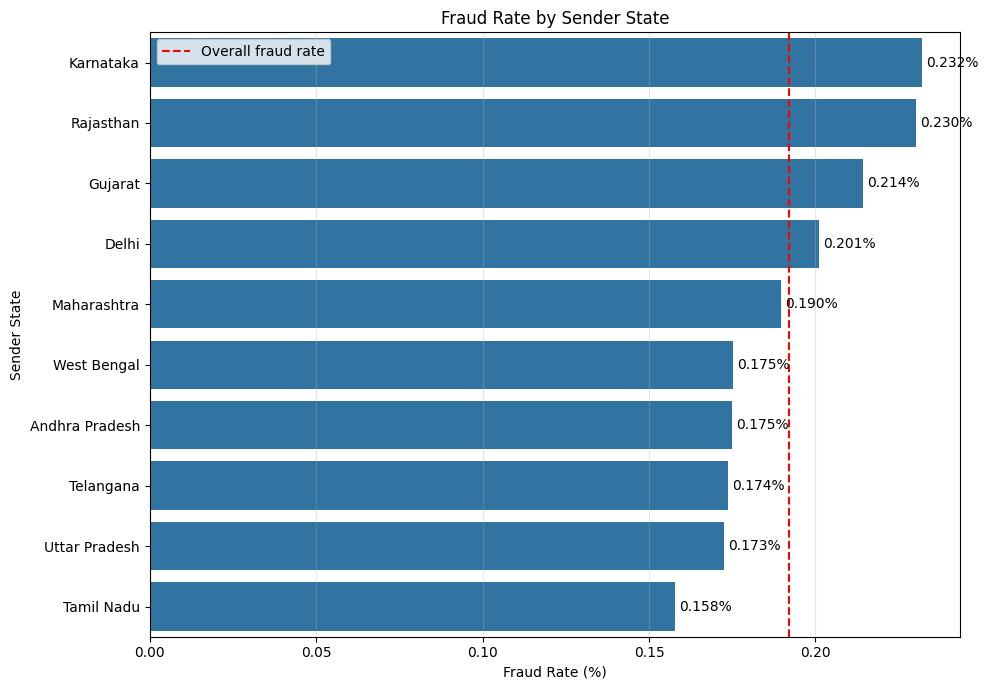

In [139]:
plt.figure(figsize=(10, 7))

ax = sns.barplot(
    data=state_analysis.reset_index(),
    x="fraud_rate_percent",
    y="sender_state"
)

ax.axvline(
    x=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f%%",
    padding=3
)

plt.xlabel("Fraud Rate (%)")
plt.ylabel("Sender State")
plt.title("Fraud Rate by Sender State")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [140]:
sender_age_analysis = df.groupby("sender_age_group").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

sender_age_analysis["fraud_rate_percent"] = (
    sender_age_analysis["fraud_transactions"]
    / sender_age_analysis["total_transactions"] * 100
)

print(sender_age_analysis.round(3))

                  total_transactions  fraud_transactions  fraud_rate_percent
sender_age_group                                                            
18-25                          62345                 143               0.229
26-35                          87432                 163               0.186
36-45                          62873                 116               0.184
46-55                          24841                  31               0.125
56+                            12509                  27               0.216


What do we observe?
1. 18–25 has the highest observed fraud rate: 0.229%.
2. 56+ also has a relatively high rate: 0.216%, but only 27 fraud cases.
3. 46–55 has the lowest observed rate: 0.125%.
4. 26–35 has the highest fraud count: 163, because it has the largest transaction volume.
Important interpretation
The 18–25 group has the highest observed rate, but that does not mean younger customers are inherently more likely to commit fraud. These are descriptive patterns in this dataset.

Age should not become an automatic blocking criterion. We should also assess whether including age features is appropriate and examine model performance across age groups.

Finding to record:
Sender-age fraud rates vary across the dataset. The 18–25 group has the highest observed rate (0.229%), while the 46–55 group has the lowest (0.125%). The 26–35 group contributes the largest number of fraud-labelled transactions (163). These associations are descriptive and should not be used to justify age-based blocking.

In [141]:
receiver_age_analysis = df.groupby("receiver_age_group").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

receiver_age_analysis["fraud_rate_percent"] = (
    receiver_age_analysis["fraud_transactions"]
    / receiver_age_analysis["total_transactions"] * 100
)

print(receiver_age_analysis.round(3))

                    total_transactions  fraud_transactions  fraud_rate_percent
receiver_age_group                                                            
18-25                            62611                 132               0.211
26-35                            87864                 148               0.168
36-45                            62151                 125               0.201
46-55                            24823                  57               0.230
56+                              12551                  18               0.143


What do we observe?
1. 46–55 has the highest observed receiver-age fraud rate: 0.230%.
2. 56+ has the lowest: 0.143%.
3. 26–35 has the highest fraud count: 148 cases, alongside the largest transaction volume.
4. The receiver-age pattern differs from the sender-age pattern:
   - Sender age: 18–25 has the highest rate (0.229%).
   - Receiver age: 46–55 has the highest rate (0.230%).
Finding to record:
Receiver-age fraud rates vary across the dataset. The 46–55 group has the highest observed rate (0.230%), while the 56+ group has the lowest (0.143%). The 26–35 group contributes the largest number of fraud-labelled transactions (148). These are descriptive associations, not evidence that a particular age group is responsible for fraud.

Age-related patterns should be treated cautiously. We should not use age alone to block or challenge a transaction.

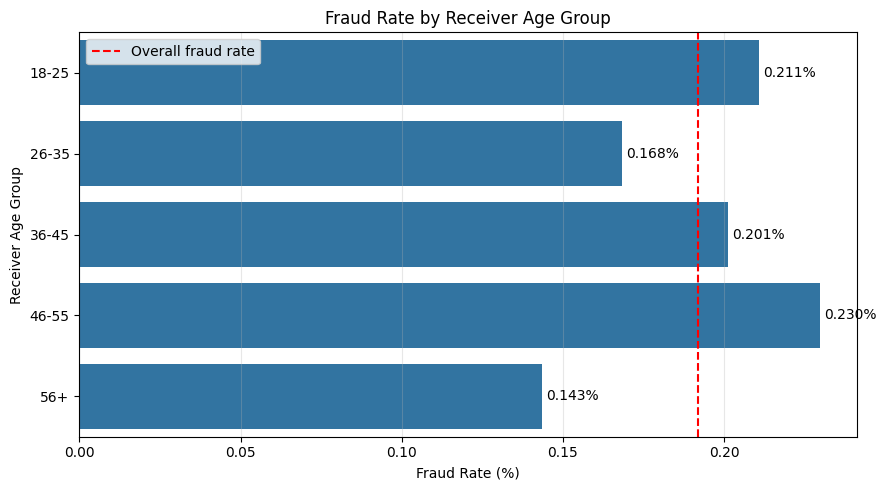

In [142]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=receiver_age_analysis.reset_index(),
    x="fraud_rate_percent",
    y="receiver_age_group"
)

ax.axvline(
    x=(fraud_count / total_transactions) * 100,
    linestyle="--",
    color="red",
    label="Overall fraud rate"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f%%",
    padding=3
)

plt.xlabel("Fraud Rate (%)")
plt.ylabel("Receiver Age Group")
plt.title("Fraud Rate by Receiver Age Group")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [143]:
# Identify IQR outliers
upper_bound = 3558

outliers = df[df["amount (INR)"] > upper_bound]

print("OVERALL AMOUNT OUTLIERS")
print("-----------------------")
print(f"Outlier transactions: {len(outliers):,}")
print(f"Percentage of all transactions: {len(outliers) / len(df) * 100:.2f}%")
print(f"Total value of outlier transactions: ₹{outliers['amount (INR)'].sum():,.2f}")

print("\nOUTLIERS BY FRAUD STATUS")
print("------------------------")

outlier_analysis = outliers.groupby("fraud_flag").agg(
    transaction_count=("fraud_flag", "count"),
    total_amount=("amount (INR)", "sum"),
    average_amount=("amount (INR)", "mean")
)

print(outlier_analysis.round(2))

OVERALL AMOUNT OUTLIERS
-----------------------
Outlier transactions: 21,171
Percentage of all transactions: 8.47%
Total value of outlier transactions: ₹128,083,542.00

OUTLIERS BY FRAUD STATUS
------------------------
            transaction_count  total_amount  average_amount
fraud_flag                                                 
0                       21113     127711224         6048.94
1                          58        372318         6419.28


What does this tell us?
1. The fraud-labelled transactions have a higher outlier rate: 12.08% versus 8.46%.
2. Fraud-labelled outliers have a slightly higher average amount.
3. However, 21,113 of the 21,171 outliers are genuine.
4. 422 of the 480 fraud-labelled transactions are not IQR outliers.
This is why we cannot use a simple high-amount rule to identify fraud. It would flag many genuine transactions and miss most fraud cases.

Finding to record:
Transactions above the ₹3,558 IQR boundary account for 8.47% of the dataset. Their fraud rate within this subset is higher than the dataset-wide rate, but 21,113 of these transactions are genuine. Furthermore, 422 of 480 fraud-labelled transactions fall below the boundary. Transaction amount may provide useful model information, but IQR outlier status alone is not a reliable fraud detector.

In [144]:
amount_percentiles = df.groupby("fraud_flag")["amount (INR)"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).unstack()

amount_percentiles.index = ["Genuine (0)", "Fraud (1)"]

print(amount_percentiles.round(2))

              0.25   0.50    0.75    0.90     0.95      0.99
Genuine (0)  288.0  629.0  1596.0  3235.0  4685.00   9000.62
Fraud (1)    260.0  618.5  1673.5  3953.2  5496.95  11562.24


What do we observe?
1. Median: Fraud-labelled transactions have a slightly lower median (₹618.50) than genuine transactions (₹629).
2. 75th percentile: Fraud-labelled transactions are slightly higher (₹1,673.50 vs ₹1,596).
3. 90th percentile: The fraud value is ₹3,953.20, compared with ₹3,235 for genuine transactions.
4. 95th percentile: Fraud reaches ₹5,496.95, compared with ₹4,685.
5. 99th percentile: Fraud reaches ₹11,562.24, compared with ₹9,000.62.
The difference becomes more pronounced toward the upper percentiles.
Why this matters
A model should not assume that larger transactions are automatically fraudulent. The median values are nearly identical, but the upper tails differ.

This suggests we should test:
- Raw transaction amount.
- Log-transformed transaction amount.
- Possibly amount bands.
We will compare their actual predictive contribution later rather than assuming any one transformation is better.

Finding to record:
Genuine and fraud-labelled transactions have similar median amounts. However, fraud-labelled transactions show higher amounts at the 75th, 90th, 95th and 99th percentiles. This suggests that the upper tail of transaction amount may contain useful predictive information, although amount alone cannot reliably distinguish fraud from genuine activity.

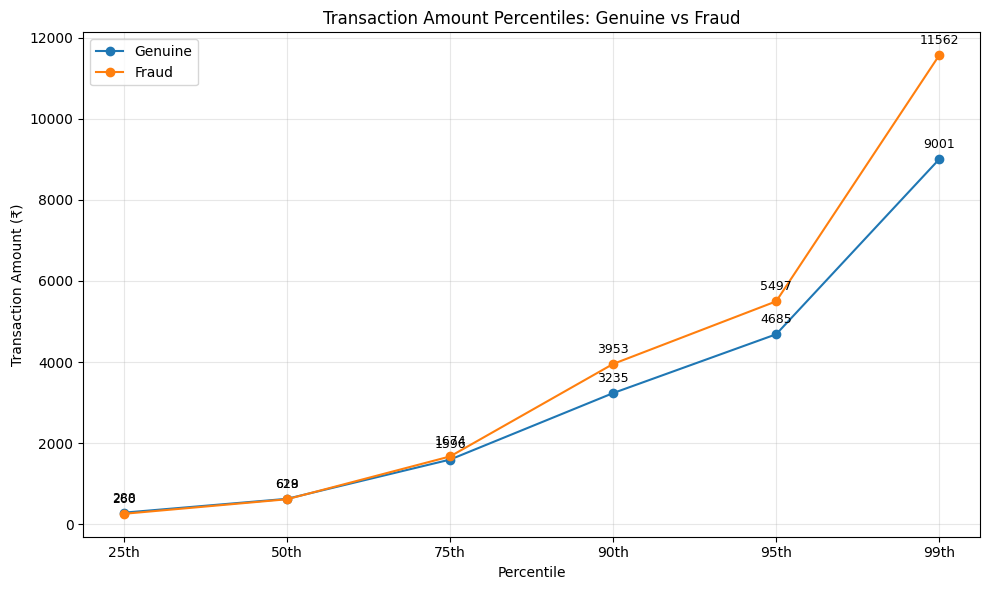

In [148]:
plt.figure(figsize=(10, 6))

percentile_labels = ["25th", "50th", "75th", "90th", "95th", "99th"]


plt.plot(
    percentile_labels,
    amount_percentiles.loc["Genuine (0)"],
    marker="o",
    label="Genuine"
)


for x, y in zip(percentile_labels, amount_percentiles.loc["Genuine (0)"]):
    plt.annotate(
        f'{y:.0f}',  
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha='center',
        fontsize=9,
        color='black'
    )


plt.plot(
    percentile_labels,
    amount_percentiles.loc["Fraud (1)"],
    marker="o",
    label="Fraud"
)


for x, y in zip(percentile_labels, amount_percentiles.loc["Fraud (1)"]):
    plt.annotate(
        f'{y:.0f}',
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha='center',
        fontsize=9,
        color='black'
    )

plt.title("Transaction Amount Percentiles: Genuine vs Fraud")
plt.xlabel("Percentile")
plt.ylabel("Transaction Amount (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


In [149]:
status_analysis = df.groupby("transaction_status").agg(
    total_transactions=("fraud_flag", "count"),
    fraud_transactions=("fraud_flag", "sum")
)

status_analysis["fraud_rate_percent"] = (
    status_analysis["fraud_transactions"]
    / status_analysis["total_transactions"] * 100
)

print(status_analysis.round(3))

                    total_transactions  fraud_transactions  fraud_rate_percent
transaction_status                                                            
FAILED                           12376                  21               0.170
SUCCESS                         237624                 459               0.193


In [150]:
# Create a working copy; preserve the original dataframe
df_clean = df.copy()

# Standardise column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df_clean.columns.tolist())

['transaction_id', 'timestamp', 'transaction_type', 'merchant_category', 'amount_inr', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'fraud_flag', 'hour_of_day', 'day_of_week', 'is_weekend', 'month']


In [151]:
df_clean.dtypes

transaction_id                object
timestamp             datetime64[ns]
transaction_type              object
merchant_category             object
amount_inr                     int64
transaction_status            object
sender_age_group              object
receiver_age_group            object
sender_state                  object
sender_bank                   object
receiver_bank                 object
device_type                   object
network_type                  object
fraud_flag                     int64
hour_of_day                    int64
day_of_week                   object
is_weekend                     int64
month                          int32
dtype: object

In [152]:
print("FRAUD FLAG VALUES")
print(df_clean["fraud_flag"].value_counts().sort_index())

print("\nWEEKEND FLAG VALUES")
print(df_clean["is_weekend"].value_counts().sort_index())

print("\nHOUR RANGE")
print("Minimum:", df_clean["hour_of_day"].min())
print("Maximum:", df_clean["hour_of_day"].max())

print("\nMONTH RANGE")
print("Minimum:", df_clean["month"].min())
print("Maximum:", df_clean["month"].max())

print("\nAMOUNT RANGE")
print("Minimum:", df_clean["amount_inr"].min())
print("Maximum:", df_clean["amount_inr"].max())

FRAUD FLAG VALUES
fraud_flag
0    249520
1       480
Name: count, dtype: int64

WEEKEND FLAG VALUES
is_weekend
0    178663
1     71337
Name: count, dtype: int64

HOUR RANGE
Minimum: 0
Maximum: 23

MONTH RANGE
Minimum: 1
Maximum: 12

AMOUNT RANGE
Minimum: 10
Maximum: 42099


In [153]:
timestamp_checks = pd.DataFrame({
    "hour_matches": (
        df_clean["hour_of_day"] == df_clean["timestamp"].dt.hour
    ),
    "day_matches": (
        df_clean["day_of_week"] == df_clean["timestamp"].dt.day_name()
    ),
    "weekend_matches": (
        df_clean["is_weekend"] == (
            df_clean["timestamp"].dt.dayofweek >= 5
        ).astype(int)
    ),
    "month_matches": (
        df_clean["month"] == df_clean["timestamp"].dt.month
    )
})

print(timestamp_checks.sum())
print("\nTotal rows:", len(timestamp_checks))
print("\nMismatches:")
print((~timestamp_checks).sum())


hour_matches       250000
day_matches        250000
weekend_matches    250000
month_matches      250000
dtype: int64

Total rows: 250000

Mismatches:
hour_matches       0
day_matches        0
weekend_matches    0
month_matches      0
dtype: int64


## Problem Statement 4 — Detect Fraud with Supervised Learning

- 4.1 Time-Based Train, Validation and Test Split

In [154]:
# Sort transactions from oldest to newest
df_sorted = df_clean.sort_values("timestamp").reset_index(drop=True)

# Define split positions
train_end = int(len(df_sorted) * 0.70)
val_end = int(len(df_sorted) * 0.85)

# Split the data chronologically
train_df = df_sorted.iloc[:train_end].copy()
val_df = df_sorted.iloc[train_end:val_end].copy()
test_df = df_sorted.iloc[val_end:].copy()

# Display split sizes and fraud counts
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name} Set")
    print("Total transactions:", len(data))
    print("Fraud transactions:", data["fraud_flag"].sum())
    print("Fraud rate:", round(data["fraud_flag"].mean() * 100, 4), "%")


Training Set
Total transactions: 175000
Fraud transactions: 325
Fraud rate: 0.1857 %

Validation Set
Total transactions: 37500
Fraud transactions: 88
Fraud rate: 0.2347 %

Testing Set
Total transactions: 37500
Fraud transactions: 67
Fraud rate: 0.1787 %


## 4.2 Define Target Variable and Eligible Features

In [155]:
# Target: what the model must predict
target = "fraud_flag"

# Columns that must not be used as model inputs
excluded_columns = [
    "transaction_id",
    "timestamp",
    "transaction_status",
    "fraud_flag"
]

# Select eligible input features
feature_columns = [
    col for col in train_df.columns
    if col not in excluded_columns
]

# Separate features and target
X_train = train_df[feature_columns]
y_train = train_df[target]

X_val = val_df[feature_columns]
y_val = val_df[target]

X_test = test_df[feature_columns]
y_test = test_df[target]

print("Selected features:")
print(feature_columns)

print("\nNumber of input features:", len(feature_columns))
print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)
print("Testing feature shape:", X_test.shape)

Selected features:
['transaction_type', 'merchant_category', 'amount_inr', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'hour_of_day', 'day_of_week', 'is_weekend', 'month']

Number of input features: 14
Training feature shape: (175000, 14)
Validation feature shape: (37500, 14)
Testing feature shape: (37500, 14)


### Identify Numerical and Categorical Features

In [156]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['amount_inr', 'hour_of_day', 'is_weekend']

Categorical features:
['transaction_type', 'merchant_category', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'day_of_week']

Number of numerical features: 3
Number of categorical features: 10


### 4.4 Preprocessing Numerical and Categorical Features

In [157]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

### 4.5 Model 1 — Logistic Regression with Class Weights

In [161]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

### 4.6 Train the Logistic Regression Model

In [162]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


### 4.7 Generate Fraud Probabilities on Validation Data

In [163]:
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

print("Number of validation predictions:", len(y_val_prob))
print("Minimum fraud probability:", y_val_prob.min())
print("Maximum fraud probability:", y_val_prob.max())
print("First 10 fraud probabilities:")
print(y_val_prob[:10])

Number of validation predictions: 37500
Minimum fraud probability: 0.13638991583432256
Maximum fraud probability: 0.8775375764836957
First 10 fraud probabilities:
[0.64452917 0.62367745 0.57471705 0.52765888 0.59863391 0.53199518
 0.40752801 0.53670833 0.51258289 0.48669734]


### 4.8 Initial Logistic Regression Evaluation

In [164]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

y_val_pred_05 = (y_val_prob >= 0.5).astype(int)

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, y_val_prob), 6))

print("Precision:",
      round(precision_score(y_val, y_val_pred_05, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_val, y_val_pred_05, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_val, y_val_pred_05, zero_division=0), 4))

PR-AUC (Average Precision): 0.003394
Precision: 0.0022
Recall: 0.3977
F1 Score: 0.0043


In [165]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_val_pred_05)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Confusion Matrix:
[[21349 16063]
 [   53    35]]

True Negatives: 21349
False Positives: 16063
False Negatives: 53
True Positives: 35


### 4.10 Compare Logistic Regression Against Random Baseline

In [166]:
random_baseline_pr_auc = y_val.mean()

logistic_pr_auc = average_precision_score(
    y_val, y_val_prob
)

print("Random baseline PR-AUC:",
      round(random_baseline_pr_auc, 6))

print("Logistic Regression PR-AUC:",
      round(logistic_pr_auc, 6))

print("Improvement over random baseline:",
      round(logistic_pr_auc / random_baseline_pr_auc, 2),
      "times")

Random baseline PR-AUC: 0.002347
Logistic Regression PR-AUC: 0.003394
Improvement over random baseline: 1.45 times


### 4.11 Logistic Regression — Threshold Analysis

In [167]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

for threshold in thresholds:
    predictions = (y_val_prob >= threshold).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"Flagged: {predictions.sum()}"
    )

Threshold: 0.2 | Precision: 0.0024 | Recall: 1.0000 | Flagged: 37441
Threshold: 0.3 | Precision: 0.0023 | Recall: 0.9318 | Flagged: 35934
Threshold: 0.4 | Precision: 0.0023 | Recall: 0.7386 | Flagged: 28870
Threshold: 0.5 | Precision: 0.0022 | Recall: 0.3977 | Flagged: 16098
Threshold: 0.6 | Precision: 0.0034 | Recall: 0.1818 | Flagged: 4759
Threshold: 0.7 | Precision: 0.0057 | Recall: 0.0341 | Flagged: 529
Threshold: 0.8 | Precision: 0.0000 | Recall: 0.0000 | Flagged: 15


- At threshold 0.2, the model detects all 88 fraud cases, but flags almost every transaction.



- At threshold 0.5, it detects 35 fraud cases and flags 16,098 transactions.



- At threshold 0.7, it flags only 529 transactions, but detects just 3 fraud cases.

Our conclusion: There is no good threshold in this initial model that gives us both high fraud detection and acceptable false alarms.

Do not select 0.2 just because recall is 100%. That would mean challenging almost the entire payment population.

### 4.12 Precision and Recall Across Thresholds

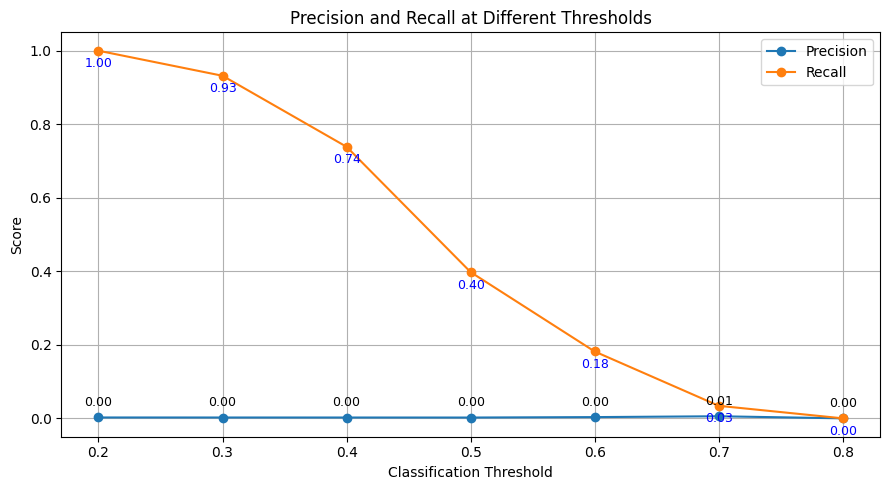

In [170]:
plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision_values, marker="o", label="Precision")
plt.plot(thresholds, recall_values, marker="o", label="Recall")

# Add labels for Precision
for x, y in zip(thresholds, precision_values):
    plt.annotate(
        f'{y:.2f}',
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha='center',
        fontsize=9,
        color='black'
    )

# Add labels for Recall
for x, y in zip(thresholds, recall_values):
    plt.annotate(
        f'{y:.2f}',
        (x, y),
        textcoords="offset points",
        xytext=(0, -12),
        ha='center',
        fontsize=9,
        color='blue'
    )

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall at Different Thresholds")
plt.xticks(thresholds)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Observation:**

The Logistic Regression model shows a significant trade-off between
fraud detection and false alarms. Lowering the threshold increases
fraud recall but also causes a very large number of genuine
transactions to be flagged. Increasing the threshold reduces the
number of flagged transactions but causes more fraud cases to be
missed.

**Conclusion:**

The current Logistic Regression model does not provide a satisfactory
balance between fraud detection and false alarms. We will compare it
with other supervised models before selecting a final model and
decision policy.

### 4.13 Model 2 — Random Forest with Class Weights

In [171]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

### 4.14 Train the Random Forest Model

In [172]:
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


### 4.15 Generate Random Forest Fraud Probabilities

In [173]:
rf_val_prob = random_forest_model.predict_proba(X_val)[:, 1]

print("Number of validation predictions:", len(rf_val_prob))
print("Minimum fraud probability:", rf_val_prob.min())
print("Maximum fraud probability:", rf_val_prob.max())
print("First 10 fraud probabilities:")
print(rf_val_prob[:10])

Number of validation predictions: 37500
Minimum fraud probability: 0.0
Maximum fraud probability: 0.135
First 10 fraud probabilities:
[0.005 0.    0.    0.005 0.    0.    0.    0.005 0.    0.   ]


### 4.16 Initial Random Forest Evaluation

In [174]:
rf_val_pred_05 = (rf_val_prob >= 0.5).astype(int)

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, rf_val_prob), 6))

print("Precision:",
      round(precision_score(y_val, rf_val_pred_05, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_val, rf_val_pred_05, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_val, rf_val_pred_05, zero_division=0), 4))

PR-AUC (Average Precision): 0.002693
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


### 4.17 Random Forest — Threshold Analysis

In [175]:
rf_thresholds = [0.001, 0.005, 0.01, 0.02, 0.03, 0.05, 0.10]

for threshold in rf_thresholds:
    predictions = (rf_val_prob >= threshold).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    print(
        f"Threshold: {threshold:.3f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"Flagged: {predictions.sum()}"
    )

Threshold: 0.001 | Precision: 0.0033 | Recall: 0.3636 | Flagged: 9591
Threshold: 0.005 | Precision: 0.0033 | Recall: 0.3636 | Flagged: 9591
Threshold: 0.010 | Precision: 0.0031 | Recall: 0.1023 | Flagged: 2945
Threshold: 0.020 | Precision: 0.0019 | Recall: 0.0114 | Flagged: 538
Threshold: 0.030 | Precision: 0.0052 | Recall: 0.0114 | Flagged: 191
Threshold: 0.050 | Precision: 0.0000 | Recall: 0.0000 | Flagged: 31
Threshold: 0.100 | Precision: 0.0000 | Recall: 0.0000 | Flagged: 4


### 4.18 Supervised Model Comparison — Initial Results

In [176]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "PR-AUC": [
        average_precision_score(y_val, y_val_prob),
        average_precision_score(y_val, rf_val_prob)
    ],
    "Precision at 0.5": [
        precision_score(y_val, y_val_pred_05, zero_division=0),
        precision_score(y_val, rf_val_pred_05, zero_division=0)
    ],
    "Recall at 0.5": [
        recall_score(y_val, y_val_pred_05, zero_division=0),
        recall_score(y_val, rf_val_pred_05, zero_division=0)
    ],
    "F1 at 0.5": [
        f1_score(y_val, y_val_pred_05, zero_division=0),
        f1_score(y_val, rf_val_pred_05, zero_division=0)
    ]
})

display(model_comparison.round(6))

,Model,PR-AUC,Precision at 0.5,Recall at 0.5,F1 at 0.5
0,Logistic Regression,0.003394,0.002174,0.397727,0.004325
1,Random Forest,0.002693,0.000000,0.000000,0.000000


## XG Boost 



In [177]:
import importlib.util

if importlib.util.find_spec("xgboost") is not None:
    print("XGBoost is installed.")
else:
    print("XGBoost is not installed.")

XGBoost is installed.


In [178]:
from xgboost import XGBClassifier

# Calculate the imbalance ratio using training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative transactions:", negative_count)
print("Fraud transactions:", positive_count)
print("Scale positive weight:", round(scale_pos_weight, 2))

Negative transactions: 174675
Fraud transactions: 325
Scale positive weight: 537.46


In [179]:
from xgboost import XGBClassifier

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1
    ))
])

In [180]:
xgb_model.fit(X_train, y_train)

print("XGBoost training completed successfully.")

XGBoost training completed successfully.


In [181]:
xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]

print("Number of validation predictions:", len(xgb_val_prob))
print("Minimum fraud probability:", xgb_val_prob.min())
print("Maximum fraud probability:", xgb_val_prob.max())
print("First 10 probabilities:", xgb_val_prob[:10])

Number of validation predictions: 37500
Minimum fraud probability: 0.0052413046
Maximum fraud probability: 0.89917135
First 10 probabilities: [0.2299571  0.51088464 0.31232837 0.25984186 0.40748596 0.43501148
 0.21133888 0.58406734 0.38426092 0.47625718]


In [182]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

xgb_val_pred_05 = (xgb_val_prob >= 0.5).astype(int)

print("XGBoost PR-AUC:",
      average_precision_score(y_val, xgb_val_prob))

print("Precision at 0.5:",
      precision_score(y_val, xgb_val_pred_05, zero_division=0))

print("Recall at 0.5:",
      recall_score(y_val, xgb_val_pred_05, zero_division=0))

print("F1 at 0.5:",
      f1_score(y_val, xgb_val_pred_05, zero_division=0))

XGBoost PR-AUC: 0.0025422694537380122
Precision at 0.5: 0.0027243832299076736
Recall at 0.5: 0.20454545454545456
F1 at 0.5: 0.005377147124719941


In [183]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "PR-AUC": [
        average_precision_score(y_val, y_val_prob),
        average_precision_score(y_val, rf_val_prob),
        average_precision_score(y_val, xgb_val_prob)
    ],
    "Precision at 0.5": [
        precision_score(y_val, y_val_pred_05, zero_division=0),
        precision_score(y_val, rf_val_pred_05, zero_division=0),
        precision_score(y_val, xgb_val_pred_05, zero_division=0)
    ],
    "Recall at 0.5": [
        recall_score(y_val, y_val_pred_05, zero_division=0),
        recall_score(y_val, rf_val_pred_05, zero_division=0),
        recall_score(y_val, xgb_val_pred_05, zero_division=0)
    ],
    "F1 at 0.5": [
        f1_score(y_val, y_val_pred_05, zero_division=0),
        f1_score(y_val, rf_val_pred_05, zero_division=0),
        f1_score(y_val, xgb_val_pred_05, zero_division=0)
    ]
})

display(model_comparison.round(6))

,Model,PR-AUC,Precision at 0.5,Recall at 0.5,F1 at 0.5
0,Logistic Regression,0.003394,0.002174,0.397727,0.004325
1,Random Forest,0.002693,0.000000,0.000000,0.000000
2,XGBoost,0.002542,0.002724,0.204545,0.005377


What have we learned?
1. Logistic Regression: Best PR-AUC and highest recall at 0.5. It currently ranks fraud cases better than the other models.
2. Random Forest: No fraud predictions at 0.5, despite producing probabilities below 0.135.
3. XGBoost: Highest precision and F1 at 0.5, but lower PR-AUC and recall than Logistic Regression.
Important conclusion
We should not select the final model using only threshold 0.5. Different models produce different probability distributions, and the default threshold may not be suitable for fraud detection.

### 4.20 Logistic Regression Without Class Weighting

In [184]:
logistic_unweighted = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [185]:
logistic_unweighted.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [186]:
logistic_unweighted_val_prob = logistic_unweighted.predict_proba(X_val)[:, 1]


In [187]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

unweighted_pred = (logistic_unweighted_val_prob >= 0.5).astype(int)

print("PR-AUC:", average_precision_score(y_val, logistic_unweighted_val_prob))
print("Precision:", precision_score(y_val, unweighted_pred, zero_division=0))
print("Recall:", recall_score(y_val, unweighted_pred, zero_division=0))
print("F1-score:", f1_score(y_val, unweighted_pred, zero_division=0))

PR-AUC: 0.0050128881321764894
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [188]:
print("Minimum probability:", logistic_unweighted_val_prob.min())
print("Maximum probability:", logistic_unweighted_val_prob.max())
print("Probability percentiles:")
print(np.percentile(logistic_unweighted_val_prob, [50, 90, 95, 99, 99.5, 99.9]))

Minimum probability: 0.0004904802926214158
Maximum probability: 0.01385338569663093
Probability percentiles:
[0.00172884 0.00273744 0.00313439 0.00411115 0.00460489 0.00596881]


In [189]:
from sklearn.metrics import precision_score, recall_score

thresholds = [0.001, 0.002, 0.003, 0.004, 0.005,
              0.006, 0.008, 0.010]

for threshold in thresholds:
    predictions = (
        logistic_unweighted_val_prob >= threshold
    ).astype(int)

    print(
        f"Threshold: {threshold:.3f} | "
        f"Precision: {precision_score(y_val, predictions, zero_division=0):.4f} | "
        f"Recall: {recall_score(y_val, predictions, zero_division=0):.4f} | "
        f"Flagged: {predictions.sum()}"
    )

Threshold: 0.001 | Precision: 0.0024 | Recall: 0.9432 | Flagged: 34827
Threshold: 0.002 | Precision: 0.0020 | Recall: 0.2841 | Flagged: 12800
Threshold: 0.003 | Precision: 0.0030 | Recall: 0.0795 | Flagged: 2371
Threshold: 0.004 | Precision: 0.0069 | Recall: 0.0341 | Flagged: 437
Threshold: 0.005 | Precision: 0.0083 | Recall: 0.0114 | Flagged: 120
Threshold: 0.006 | Precision: 0.0294 | Recall: 0.0114 | Flagged: 34
Threshold: 0.008 | Precision: 0.1111 | Recall: 0.0114 | Flagged: 9
Threshold: 0.010 | Precision: 0.2000 | Recall: 0.0114 | Flagged: 5


**Finding — Effect of Class Weighting on Logistic Regression**

The unweighted Logistic Regression model achieved a higher validation PR-AUC (0.005013) than the class-weighted model (0.003394). However, its predicted fraud probabilities were much lower, with a maximum of approximately 0.0139.

At the default threshold of 0.5, the unweighted model detected no fraud. Lowering the threshold increased recall but also caused a large number of transactions to be flagged.

This demonstrates that class weighting changes the probability distribution and that the default 0.5 threshold is not suitable for every model. Final threshold selection must consider fraud detection, false alerts and financial cost.

### 4.21 Simple Rule-Based Fraud Baseline

In [190]:
amount_threshold = train_df["amount_inr"].quantile(0.99)

print("99th percentile amount threshold: ₹", amount_threshold)

99th percentile amount threshold: ₹ 8964.020000000019


In [191]:
rule_val_pred = (
    X_val["amount_inr"] > amount_threshold
).astype(int)

print("Total validation transactions:", len(rule_val_pred))
print("Transactions flagged:", rule_val_pred.sum())
print("Transactions not flagged:", (rule_val_pred == 0).sum())

Total validation transactions: 37500
Transactions flagged: 396
Transactions not flagged: 37104


In [192]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Precision:", precision_score(y_val, rule_val_pred, zero_division=0))
print("Recall:", recall_score(y_val, rule_val_pred, zero_division=0))
print("F1-score:", f1_score(y_val, rule_val_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rule_val_pred))

Precision: 0.005050505050505051
Recall: 0.022727272727272728
F1-score: 0.008264462809917356

Confusion Matrix:
[[37018   394]
 [   86     2]]


**Finding — Simple Amount-Based Rule**

A rule that flags transactions above the training-set 99th percentile amount (₹8,964.02) flagged 396 validation transactions.

It detected only 2 of the 88 fraudulent transactions, giving a recall of 2.27% and precision of 0.51%. It missed 86 fraudulent transactions and incorrectly flagged 394 genuine transactions.

This shows that transaction amount alone is insufficient for reliable fraud detection. More contextual information is needed.

### 4.22 Overall Supervised Model Comparison

In [193]:
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

model_results = []

models = {
    "Logistic Regression (Weighted)": (y_val_prob, 0.5),
    "Logistic Regression (Unweighted)": (logistic_unweighted_val_prob, 0.5),
    "Random Forest (Weighted)": (rf_val_prob, 0.5),
    "XGBoost (Weighted)": (xgb_val_prob, 0.5)
}

for model_name, (probabilities, threshold) in models.items():
    predictions = (probabilities >= threshold).astype(int)

    model_results.append({
        "Model": model_name,
        "PR-AUC": average_precision_score(y_val, probabilities),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0),
        "Flagged": predictions.sum()
    })

model_results.append({
    "Model": "Amount-Based Rule",
    "PR-AUC": None,
    "Precision": precision_score(y_val, rule_val_pred, zero_division=0),
    "Recall": recall_score(y_val, rule_val_pred, zero_division=0),
    "F1-score": f1_score(y_val, rule_val_pred, zero_division=0),
    "Flagged": rule_val_pred.sum()
})

comparison_df = pd.DataFrame(model_results)

comparison_df.round(6)

,Model,PR-AUC,Precision,Recall,F1-score,Flagged
0,Logistic Regression (Weighted),0.003394,0.002174,0.397727,0.004325,16098
1,Logistic Regression (Unweighted),0.005013,0.000000,0.000000,0.000000,0
2,Random Forest (Weighted),0.002693,0.000000,0.000000,0.000000,0
3,XGBoost (Weighted),0.002542,0.002724,0.204545,0.005377,6607
4,Amount-Based Rule,NaN,0.005051,0.022727,0.008264,396


**Finding — Initial Supervised Model Comparison**

The unweighted Logistic Regression achieved the highest validation PR-AUC (0.005013), while weighted Logistic Regression achieved the highest recall at the default threshold of 0.5 (39.77%).

However, the models produced many false alerts or failed to detect fraud at the default threshold. XGBoost achieved the highest precision and F1-score among the three weighted models, but did not achieve the highest PR-AUC.

The amount-based rule detected only 2 of 88 validation fraud cases.

Overall, the initial models show limited fraud-ranking performance. Further imbalance-handling experiments and threshold evaluation are necessary before selecting a final model.

In [195]:
from imblearn.over_sampling import SMOTENC

print("SMOTENC is available.")

SMOTENC is available.


In [196]:
categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_features
]

print("Categorical feature indices:", categorical_indices)
print("Number of categorical features:", len(categorical_indices))

Categorical feature indices: [0, 1, 3, 4, 5, 6, 7, 8, 9, 11]
Number of categorical features: 10


In [197]:
from imblearn.over_sampling import SMOTENC

smote_nc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.5,
    random_state=42
)

print("SMOTENC configured successfully.")

SMOTENC configured successfully.


In [198]:
print("Original training class distribution:")
print(y_train.value_counts().sort_index())

print("\nOriginal training fraud percentage:")
print(round(y_train.mean() * 100, 4), "%")

Original training class distribution:
fraud_flag
0    174675
1       325
Name: count, dtype: int64

Original training fraud percentage:
0.1857 %


In [199]:
smote_nc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.05,
    random_state=42
)

print("SMOTENC sampling strategy:", smote_nc.sampling_strategy)


SMOTENC sampling strategy: 0.05


In [200]:
X_train_smote, y_train_smote = smote_nc.fit_resample(
    X_train,
    y_train
)

print("Before SMOTENC:")
print(y_train.value_counts().sort_index())

print("\nAfter SMOTENC:")
print(y_train_smote.value_counts().sort_index())

print("\nNew training shape:", X_train_smote.shape)

Before SMOTENC:
fraud_flag
0    174675
1       325
Name: count, dtype: int64

After SMOTENC:
fraud_flag
0    174675
1      8733
Name: count, dtype: int64

New training shape: (183408, 14)


## 4.23 — Retrain the corrected Logistic Regression model

In [213]:
logistic_model.fit(X_train, y_train)

print("Corrected Logistic Regression model trained successfully.")

Corrected Logistic Regression model trained successfully.


In [214]:
logistic_val_prob = logistic_model.predict_proba(X_val)[:, 1]

print("Validation predictions:", len(logistic_val_prob))
print("Minimum probability:", logistic_val_prob.min())
print("Maximum probability:", logistic_val_prob.max())

Validation predictions: 37500
Minimum probability: 0.11985948709476801
Maximum probability: 0.8583267359321297


In [215]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

logistic_val_pred = (logistic_val_prob >= 0.5).astype(int)

print("PR-AUC:", average_precision_score(y_val, logistic_val_prob))
print("Precision:", precision_score(y_val, logistic_val_pred, zero_division=0))
print("Recall:", recall_score(y_val, logistic_val_pred, zero_division=0))
print("F1-score:", f1_score(y_val, logistic_val_pred, zero_division=0))

PR-AUC: 0.00343102693669962
Precision: 0.002232350479025207
Recall: 0.2727272727272727
F1-score: 0.004428452809299751


In [216]:
random_forest_model.fit(X_train, y_train)

print("Corrected Random Forest model trained successfully.")

Corrected Random Forest model trained successfully.


In [217]:
rf_val_prob = random_forest_model.predict_proba(X_val)[:, 1]

rf_val_pred = (rf_val_prob >= 0.5).astype(int)

print("Random Forest — Validation Results")
print("PR-AUC:", average_precision_score(y_val, rf_val_prob))
print("Precision:", precision_score(y_val, rf_val_pred, zero_division=0))
print("Recall:", recall_score(y_val, rf_val_pred, zero_division=0))
print("F1 Score:", f1_score(y_val, rf_val_pred, zero_division=0))

Random Forest — Validation Results
PR-AUC: 0.002587269726273959
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [218]:
xgb_model.fit(X_train, y_train)

print("Corrected XGBoost model trained successfully.")

Corrected XGBoost model trained successfully.


In [219]:
xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]

xgb_val_pred = (xgb_val_prob >= 0.5).astype(int)

print("XGBoost — Validation Results")
print("PR-AUC:", average_precision_score(y_val, xgb_val_prob))
print("Precision:", precision_score(y_val, xgb_val_pred, zero_division=0))
print("Recall:", recall_score(y_val, xgb_val_pred, zero_division=0))
print("F1 Score:", f1_score(y_val, xgb_val_pred, zero_division=0))

XGBoost — Validation Results
PR-AUC: 0.0020716820592893556
Precision: 0.002886836027713626
Recall: 0.056818181818181816
F1 Score: 0.005494505494505495


In [220]:
logistic_smote_model.fit(X_train, y_train)

print("Logistic Regression with SMOTENC training completed.")

Logistic Regression with SMOTENC training completed.


In [221]:
smote_val_prob = logistic_smote_model.predict_proba(X_val)[:, 1]

smote_val_pred = (smote_val_prob >= 0.5).astype(int)

print("Logistic Regression with SMOTENC — Validation Results")
print("PR-AUC:", average_precision_score(y_val, smote_val_prob))
print("Precision:", precision_score(y_val, smote_val_pred, zero_division=0))
print("Recall:", recall_score(y_val, smote_val_pred, zero_division=0))
print("F1 Score:", f1_score(y_val, smote_val_pred, zero_division=0))

Logistic Regression with SMOTENC — Validation Results
PR-AUC: 0.00255268911049123
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [222]:
logistic_unweighted.fit(X_train, y_train)

print("Corrected unweighted Logistic Regression trained.")

Corrected unweighted Logistic Regression trained.


In [223]:
unweighted_val_prob = logistic_unweighted.predict_proba(X_val)[:, 1]

unweighted_val_pred = (unweighted_val_prob >= 0.5).astype(int)

print("Unweighted Logistic Regression — Validation Results")
print("PR-AUC:", average_precision_score(y_val, unweighted_val_prob))
print("Precision:", precision_score(y_val, unweighted_val_pred, zero_division=0))
print("Recall:", recall_score(y_val, unweighted_val_pred, zero_division=0))
print("F1 Score:", f1_score(y_val, unweighted_val_pred, zero_division=0))

Unweighted Logistic Regression — Validation Results
PR-AUC: 0.004747540582871765
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


### final comparision 


In [224]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression (Weighted)",
        "PR-AUC": average_precision_score(y_val, logistic_val_prob),
        "Precision": precision_score(y_val, logistic_val_prob >= 0.5, zero_division=0),
        "Recall": recall_score(y_val, logistic_val_prob >= 0.5, zero_division=0),
        "F1": f1_score(y_val, logistic_val_prob >= 0.5, zero_division=0)
    },
    {
        "Model": "Logistic Regression (Unweighted)",
        "PR-AUC": average_precision_score(y_val, unweighted_val_prob),
        "Precision": precision_score(y_val, unweighted_val_pred, zero_division=0),
        "Recall": recall_score(y_val, unweighted_val_pred, zero_division=0),
        "F1": f1_score(y_val, unweighted_val_pred, zero_division=0)
    },
    {
        "Model": "Random Forest (Weighted)",
        "PR-AUC": average_precision_score(y_val, rf_val_prob),
        "Precision": precision_score(y_val, rf_val_pred, zero_division=0),
        "Recall": recall_score(y_val, rf_val_pred, zero_division=0),
        "F1": f1_score(y_val, rf_val_pred, zero_division=0)
    },
    {
        "Model": "XGBoost (Weighted)",
        "PR-AUC": average_precision_score(y_val, xgb_val_prob),
        "Precision": precision_score(y_val, xgb_val_pred, zero_division=0),
        "Recall": recall_score(y_val, xgb_val_pred, zero_division=0),
        "F1": f1_score(y_val, xgb_val_pred, zero_division=0)
    },
    {
        "Model": "Logistic Regression (SMOTENC)",
        "PR-AUC": average_precision_score(y_val, smote_val_prob),
        "Precision": precision_score(y_val, smote_val_pred, zero_division=0),
        "Recall": recall_score(y_val, smote_val_pred, zero_division=0),
        "F1": f1_score(y_val, smote_val_pred, zero_division=0)
    }
])

display(model_comparison.round(6))

,Model,PR-AUC,Precision,Recall,F1
0,Logistic Regression (Weighted),0.003431,0.002232,0.272727,0.004428
1,Logistic Regression (Unweighted),0.004748,0.000000,0.000000,0.000000
2,Random Forest (Weighted),0.002587,0.000000,0.000000,0.000000
3,XGBoost (Weighted),0.002072,0.002887,0.056818,0.005495
4,Logistic Regression (SMOTENC),0.002553,0.000000,0.000000,0.000000


In [225]:
amount_rule_results = pd.DataFrame([{
    "Model": "Amount Rule (99th percentile)",
    "PR-AUC": np.nan,
    "Precision": 0.005051,
    "Recall": 0.022727,
    "F1": 0.008264
}])

final_model_comparison = pd.concat(
    [model_comparison, amount_rule_results],
    ignore_index=True
)

display(final_model_comparison.round(6))

,Model,PR-AUC,Precision,Recall,F1
0,Logistic Regression (Weighted),0.003431,0.002232,0.272727,0.004428
1,Logistic Regression (Unweighted),0.004748,0.000000,0.000000,0.000000
2,Random Forest (Weighted),0.002587,0.000000,0.000000,0.000000
3,XGBoost (Weighted),0.002072,0.002887,0.056818,0.005495
4,Logistic Regression (SMOTENC),0.002553,0.000000,0.000000,0.000000
5,Amount Rule (99th percentile),NaN,0.005051,0.022727,0.008264


### 4.27 Supervised Model Comparison — Key Observations

- Unweighted Logistic Regression achieved the highest PR-AUC (0.004748), but produced no fraud predictions at the default threshold of 0.5.
- Weighted Logistic Regression achieved the highest recall (27.27%) among the supervised models.
- XGBoost achieved the highest F1-score (0.005495) among the supervised models.
- Random Forest and Logistic Regression with SMOTENC produced no fraud predictions at the default threshold.
- The amount-based rule baseline achieved an F1-score of 0.008264.

The results demonstrate that the default classification threshold is not necessarily suitable for highly imbalanced fraud detection. Model scores and decision thresholds must therefore be evaluated together.

**Limitation:** These results are based on the validation dataset. They do not establish performance on future or unseen transactions.

## Problem Statement 5 — Detect Unknown Fraud with Anomaly Detection

#### 5.1 Prepare Unlabelled Training Data

In [226]:
# Prepare training data without fraud labels

X_anomaly_train = X_train.copy()

print("Training data shape:", X_anomaly_train.shape)
print("Fraud label included:", "fraud_flag" in X_anomaly_train.columns)

Training data shape: (175000, 14)
Fraud label included: False


In [227]:
# Fit preprocessing using training data only
X_anomaly_train_processed = preprocessor.fit_transform(X_anomaly_train)

print("Processed training shape:", X_anomaly_train_processed.shape)
print("Contains only numerical values:", np.issubdtype(
    X_anomaly_train_processed.dtype, np.number
))

Processed training shape: (175000, 68)
Contains only numerical values: True


### ## 5.2 Train the Isolation Forest Model

In [228]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(X_anomaly_train_processed)

print("Isolation Forest training completed.")

Isolation Forest training completed.


In [229]:
# Transform validation data using training-fitted preprocessing
X_anomaly_val_processed = preprocessor.transform(X_val)

print("Validation data shape:", X_anomaly_val_processed.shape)

Validation data shape: (37500, 68)


In [230]:
# Generate anomaly scores for validation transactions
anomaly_scores = -isolation_forest.score_samples(
    X_anomaly_val_processed
)

print("Number of validation scores:", len(anomaly_scores))
print("Minimum anomaly score:", anomaly_scores.min())
print("Maximum anomaly score:", anomaly_scores.max())

Number of validation scores: 37500
Minimum anomaly score: 0.4007326923922295
Maximum anomaly score: 0.5437871421575752


In [231]:
# Select the top 1% highest anomaly scores
top_1_percent_count = int(len(anomaly_scores) * 0.01)

top_anomaly_indices = np.argsort(anomaly_scores)[-top_1_percent_count:]

print("Top 1% anomaly transactions:", top_1_percent_count)

Top 1% anomaly transactions: 375


In [232]:
# Evaluate fraud captured in the top 1% anomalies
frauds_in_top_anomalies = y_val.iloc[top_anomaly_indices].sum()
total_validation_frauds = y_val.sum()

anomaly_precision = frauds_in_top_anomalies / top_1_percent_count
anomaly_recall = frauds_in_top_anomalies / total_validation_frauds

print("Transactions flagged as anomalies:", top_1_percent_count)
print("Frauds found in top 1%:", frauds_in_top_anomalies)
print("Total frauds in validation set:", total_validation_frauds)
print("Precision at top 1%:", round(anomaly_precision, 4))
print("Recall at top 1%:", round(anomaly_recall, 4))

Transactions flagged as anomalies: 375
Frauds found in top 1%: 1
Total frauds in validation set: 88
Precision at top 1%: 0.0027
Recall at top 1%: 0.0114


In [233]:
# Compare top 1% fraud capture across models
top_count = top_1_percent_count

supervised_scores = {
    "Weighted Logistic Regression": logistic_val_prob,
    "Unweighted Logistic Regression": unweighted_val_prob,
    "Random Forest": rf_val_prob,
    "XGBoost": xgb_val_prob,
    "SMOTENC Logistic Regression": smote_val_prob
}

comparison_results = [{
    "Model": "Isolation Forest",
    "Frauds Found in Top 1%": int(frauds_in_top_anomalies)
}]

for model_name, scores in supervised_scores.items():
    top_indices = np.argsort(scores)[-top_count:]
    frauds_found = y_val.iloc[top_indices].sum()

    comparison_results.append({
        "Model": model_name,
        "Frauds Found in Top 1%": int(frauds_found)
    })

anomaly_supervised_comparison = pd.DataFrame(comparison_results)
display(anomaly_supervised_comparison)

,Model,Frauds Found in Top 1%
0,Isolation Forest,1
1,Weighted Logistic Regression,2
2,Unweighted Logistic Regression,2
3,Random Forest,1
4,XGBoost,0
5,SMOTENC Logistic Regression,0


## 5.3 Anomaly Detection Results and Comparison

Isolation Forest was trained on the training data without using fraud labels. It assigned anomaly scores to the validation transactions, and the top 1% (375 transactions) were selected for evaluation.

Results:
- Frauds found in the top 1%: 1 out of 88 validation frauds.
- Precision at top 1%: 0.27%.
- Recall at top 1%: 1.14%.

Comparison with supervised models:
- Isolation Forest detected 1 fraud.
- Weighted Logistic Regression detected 2 frauds.
- Unweighted Logistic Regression detected 2 frauds.
- Random Forest detected 1 fraud.
- XGBoost and SMOTENC Logistic Regression detected 0 frauds.

**Finding:** Isolation Forest identified very few fraud transactions among the highest anomaly scores. In this validation comparison, Logistic Regression captured slightly more frauds in the top 1%.

**Limitation:** Anomalous behaviour is not necessarily fraudulent behaviour. The result is specific to this dataset, validation period, and top-1% selection.

## Problem Statement 6 — Choose a Cost-Based Threshold

### 6.1 Compare Precision–Recall Curves

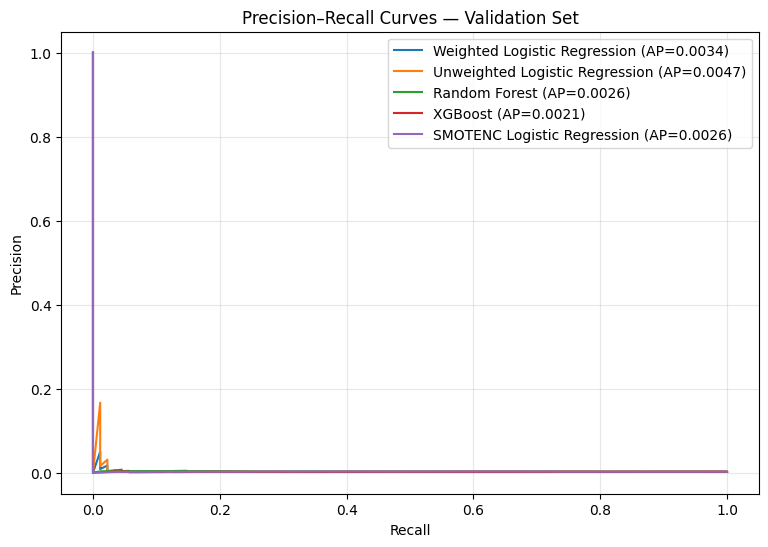

In [234]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

model_scores = {
    "Weighted Logistic Regression": logistic_val_prob,
    "Unweighted Logistic Regression": unweighted_val_prob,
    "Random Forest": rf_val_prob,
    "XGBoost": xgb_val_prob,
    "SMOTENC Logistic Regression": smote_val_prob
}

plt.figure(figsize=(9, 6))

for model_name, scores in model_scores.items():
    precision, recall, _ = precision_recall_curve(y_val, scores)
    ap = average_precision_score(y_val, scores)

    plt.plot(recall, precision, label=f"{model_name} (AP={ap:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves — Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 6.2 Precision–Recall Curve Findings

- Unweighted Logistic Regression achieved the highest Average Precision (0.0047) on the validation set.
- Weighted Logistic Regression achieved an Average Precision of 0.0034.
- Random Forest and SMOTENC Logistic Regression achieved 0.0026.
- XGBoost achieved 0.0021.
- The low Average Precision values indicate that identifying fraud reliably remains difficult.

**Note:** The highest Average Precision does not automatically mean the lowest business cost. The final decision must also consider missed-fraud costs and false-block costs.

### 6.3 Cost Assumptions and Limitations

The official problem statement does not provide numerical values for missed-fraud cost, false-block cost, or OTP challenge cost. Therefore, our team selected the following illustrative values to demonstrate cost-based decision-making.

| Cost or assumption | Value | Explanation |
|---|---:|---|
| Missed fraud (X) | ₹5,000 | Assumed loss for each missed fraudulent transaction |
| False block (Y) | ₹500 | Assumed loss for each genuine payment incorrectly blocked |
| OTP challenge (Z) | ₹5 | Assumed cost of sending one OTP |
| OTP effectiveness | 80% | Hypothetical scenario assumption, not measured evidence |

**Limitation:** These values are not provided or validated by the organisers. The cost results are scenario estimates, not actual financial savings or measured fraud-prevention outcomes. OTP effectiveness has not been established using this dataset.

In [237]:
COST_MISSED_FRAUD = 5000
COST_FALSE_BLOCK = 500
COST_OTP = 5
OTP_STOPS_FRAUD = 0.80

print("Cost assumptions loaded successfully.")

Cost assumptions loaded successfully.


In [238]:


thresholds = np.arange(0.05, 1.00, 0.05)

cost_results = []

for threshold in thresholds:
    predictions = (logistic_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    missed_fraud_cost = fn * COST_MISSED_FRAUD
    false_block_cost = fp * COST_FALSE_BLOCK
    total_cost = missed_fraud_cost + false_block_cost

    cost_results.append({
        "Threshold": threshold,
        "Missed Frauds": fn,
        "False Blocks": fp,
        "Missed Fraud Cost": missed_fraud_cost,
        "False Block Cost": false_block_cost,
        "Total Expected Cost": total_cost
    })

cost_df = pd.DataFrame(cost_results)

display(cost_df.round(2))

,Threshold,Missed Frauds,False Blocks,Missed Fraud Cost,False Block Cost,Total Expected Cost
0,0.05,0,37412,0,18706000,18706000
1,0.10,0,37412,0,18706000,18706000
2,0.15,0,37400,0,18700000,18700000
3,0.20,1,37220,5000,18610000,18615000
4,0.25,4,36471,20000,18235500,18255500
5,0.30,9,34235,45000,17117500,17162500
6,0.35,20,30089,100000,15044500,15144500
7,0.40,29,24322,145000,12161000,12306000
8,0.45,47,17385,235000,8692500,8927500
9,0.50,64,10727,320000,5363500,5683500


In [239]:
best_cost_row = cost_df.loc[
    cost_df["Total Expected Cost"].idxmin()
]

print("Best threshold:", best_cost_row["Threshold"])
print("Minimum expected cost: ₹",
      best_cost_row["Total Expected Cost"])
print("Missed frauds:", best_cost_row["Missed Frauds"])
print("False blocks:", best_cost_row["False Blocks"])

Best threshold: 0.9000000000000001
Minimum expected cost: ₹ 440000.0
Missed frauds: 88.0
False blocks: 0.0


### 6.4 Minimum-Cost Threshold Result

Using the illustrative cost assumptions, the lowest expected cost was ₹4,40,000 at a threshold of 0.90.

At this threshold:
- Missed frauds: 88
- False blocks: 0
- Expected cost: ₹4,40,000

**Important finding:** Although 0.90 produced the lowest calculated cost, it failed to detect any validation fraud transactions. Therefore, it is not suitable as a fraud-detection threshold.

The result shows that threshold selection must balance financial cost with fraud detection performance.

**Limitation:** This is an illustrative scenario based on team-defined cost assumptions, not an official or measured financial outcome.

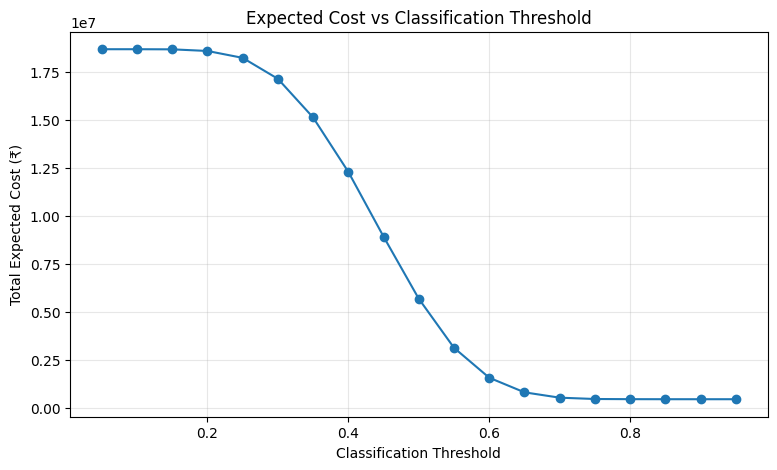

In [240]:
plt.figure(figsize=(9, 5))

plt.plot(
    cost_df["Threshold"],
    cost_df["Total Expected Cost"],
    marker="o"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Total Expected Cost (₹)")
plt.title("Expected Cost vs Classification Threshold")
plt.grid(alpha=0.3)
plt.show()

### 6.5 Expected Cost vs Threshold — Findings

- Expected cost decreases as the classification threshold increases.
- At lower thresholds, many genuine transactions are incorrectly blocked, resulting in high costs.
- At higher thresholds, false-block costs decrease, but more fraudulent transactions are missed.
- The minimum estimated cost is ₹4,40,000 at threshold 0.90.
- However, this threshold misses all 88 fraud transactions in the validation set.

**Conclusion:** Threshold selection involves a trade-off between missed fraud and false blocks. The minimum-cost threshold under our illustrative assumptions is not suitable as a standalone fraud-detection decision.

**Limitation:** The cost curve is based on team-defined assumptions, not official organiser values or measured financial outcomes.

## Problem Statement 7 — Build a 3-Band Risk Decision System

#### 7.1 Define the Three Risk Actions

The system will convert fraud-risk scores into three transaction decisions:

1. **Approve:** Low-risk transactions are approved automatically.
2. **Step-up (OTP):** Medium-risk transactions require additional verification.
3. **Block:** High-risk transactions are blocked for further review.

The two risk thresholds will be selected using validation data. The test set will remain untouched until final evaluation.

**Limitation:** OTP is treated as an additional verification step. Its actual fraud-prevention effectiveness has not been measured.

In [241]:
APPROVE_THRESHOLD = 0.30
BLOCK_THRESHOLD = 0.70

print("Approve threshold:", APPROVE_THRESHOLD)
print("Block threshold:", BLOCK_THRESHOLD)

Approve threshold: 0.3
Block threshold: 0.7


In [242]:
risk_decisions = pd.DataFrame({
    "Actual Fraud": y_val.values,
    "Fraud Score": logistic_val_prob
})

risk_decisions["Risk Action"] = np.select(
    [
        risk_decisions["Fraud Score"] < APPROVE_THRESHOLD,
        risk_decisions["Fraud Score"] < BLOCK_THRESHOLD
    ],
    [
        "Approve",
        "Step-up (OTP)"
    ],
    default="Block"
)

print("Risk action counts:")
display(risk_decisions["Risk Action"].value_counts())

print("\nRisk action percentages:")
display(
    (risk_decisions["Risk Action"].value_counts(normalize=True) * 100)
    .round(2)
)

Risk action counts:


Risk Action
Step-up (OTP)    34130
Approve           3186
Block              184
Name: count, dtype: int64


Risk action percentages:


Risk Action
Step-up (OTP)    91.01
Approve           8.50
Block             0.49
Name: proportion, dtype: float64

In [243]:
risk_summary = risk_decisions.groupby("Risk Action").agg(
    Total_Transactions=("Actual Fraud", "count"),
    Actual_Frauds=("Actual Fraud", "sum")
)

risk_summary["Genuine_Transactions"] = (
    risk_summary["Total_Transactions"] - risk_summary["Actual_Frauds"]
)

risk_summary["Fraud_Rate_Percent"] = (
    risk_summary["Actual_Frauds"] /
    risk_summary["Total_Transactions"] * 100
).round(4)

display(risk_summary)

,Total_Transactions,Actual_Frauds,Genuine_Transactions,Fraud_Rate_Percent
Risk Action,,,,
Approve,3186,9,3177,0.2825
Block,184,2,182,1.0870
Step-up (OTP),34130,77,34053,0.2256


### 7.2 Risk Band Evaluation

Using provisional thresholds of 0.30 and 0.70:

- Approve: 3,186 transactions, including 9 frauds.
- Step-up (OTP): 34,130 transactions, including 77 frauds.
- Block: 184 transactions, including 2 frauds.

The Block band has the highest fraud rate (1.0870%). However, the Step-up band contains the largest number of fraud transactions (77 out of 88).

**Finding:** The current risk bands do not clearly separate fraudulent and genuine transactions. Most transactions are assigned to the Step-up band.

**Limitation:** These are validation results using provisional thresholds. OTP prevention effectiveness has not been measured.

In [244]:
missed_frauds = (
    risk_decisions.loc[
        risk_decisions["Risk Action"] != "Block",
        "Actual Fraud"
    ].sum()
)

false_blocks = (
    (
        (risk_decisions["Risk Action"] == "Block") &
        (risk_decisions["Actual Fraud"] == 0)
    ).sum()
)

otp_challenges = (
    (risk_decisions["Risk Action"] == "Step-up (OTP)").sum()
)

missed_fraud_cost = missed_frauds * COST_MISSED_FRAUD
false_block_cost = false_blocks * COST_FALSE_BLOCK
otp_cost = otp_challenges * COST_OTP

total_expected_cost = (
    missed_fraud_cost + false_block_cost + otp_cost
)

print("Missed frauds:", missed_frauds)
print("False blocks:", false_blocks)
print("OTP challenges:", otp_challenges)
print("Missed fraud cost: ₹", missed_fraud_cost)
print("False block cost: ₹", false_block_cost)
print("OTP challenge cost: ₹", otp_cost)
print("Total expected cost: ₹", total_expected_cost)

Missed frauds: 86
False blocks: 182
OTP challenges: 34130
Missed fraud cost: ₹ 430000
False block cost: ₹ 91000
OTP challenge cost: ₹ 170650
Total expected cost: ₹ 691650


### 7.3 Cost Analysis of the Three-Band Decision System

Using the illustrative cost assumptions:

- Fraud transactions not confirmed as prevented: 86
- Genuine transactions blocked: 182
- OTP challenges: 34,130
- Estimated fraud cost: ₹4,30,000
- Estimated false-block cost: ₹91,000
- Estimated OTP cost: ₹1,70,650
- **Total estimated cost: ₹6,91,650**

**Finding:** Fraud-related costs form the largest part of the estimated total cost.

**Limitation:** No OTP prevention benefit is included because actual OTP outcomes are unavailable. The cost figures are scenario estimates based on team-defined assumptions, not actual financial losses or savings.

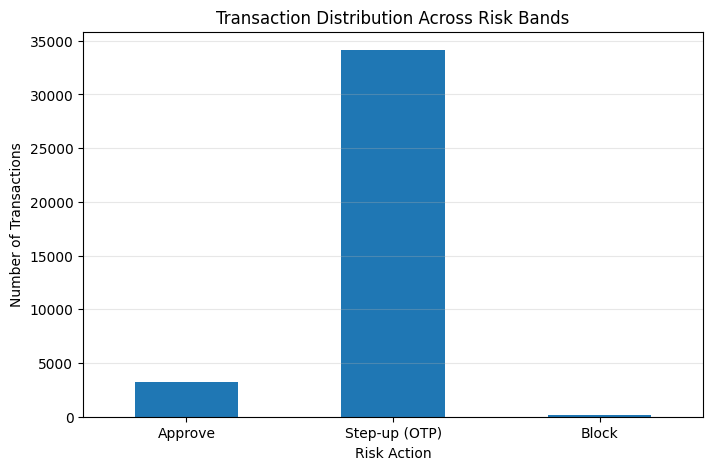

In [245]:
risk_counts = risk_decisions["Risk Action"].value_counts().reindex(
    ["Approve", "Step-up (OTP)", "Block"],
    fill_value=0
)

plt.figure(figsize=(8, 5))
risk_counts.plot(kind="bar")

plt.xlabel("Risk Action")
plt.ylabel("Number of Transactions")
plt.title("Transaction Distribution Across Risk Bands")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

### 7.4 Risk Band Distribution — Visual Finding

The transaction distribution chart shows:

- Approve: 3,186 transactions.
- Step-up (OTP): 34,130 transactions.
- Block: 184 transactions.

**Finding:** Approximately 91% of validation transactions fall into the Step-up band. This may create a high verification workload and customer friction.

**Conclusion:** The current provisional thresholds need further evaluation before deployment.

**Limitation:** These results represent the validation dataset and illustrative decision thresholds.


## Problem Statement 8 — Findings and Management Recommendations

### 8.1 Key Findings from the Analysis



**Finding 1 — Accuracy is misleading**

The dataset contains 99.808% genuine transactions and only 0.192% fraud. An always-genuine baseline achieves 99.808% accuracy but detects zero fraud.

**Finding 2 — Supervised models have limited fraud detection performance**

Unweighted Logistic Regression achieved the highest Average Precision (0.004748) on the validation set. Weighted Logistic Regression achieved 27.27% recall at the default threshold of 0.5. No model achieved strong fraud detection performance.

**Finding 3 — Anomaly detection captured very few frauds**

Isolation Forest identified only 1 fraud among the top 1% of validation anomalies. Weighted and unweighted Logistic Regression each identified 2 frauds in their respective top 1%.

**Finding 4 — Risk decisions involve business trade-offs**

The provisional three-band system assigned approximately 91% of validation transactions to Step-up (OTP). Its illustrative expected cost was ₹6,91,650 under our team-defined cost assumptions.

**Overall conclusion:** The analysis demonstrates the importance of evaluating fraud recall, precision, ranking performance and business costs instead of relying on accuracy alone.

## 8.2 Three Prioritised Management Recommendations

### Priority 1 — Improve Fraud Detection Before Full Deployment

The supervised models showed limited fraud detection performance. The organisation should improve fraud labelling and collect more reliable transaction-level behavioural data before deploying automated blocking decisions.

**Evidence:** The highest validation recall was 27.27% for Weighted Logistic Regression at the default threshold.

### Priority 2 — Introduce Risk-Based Verification Carefully

Use a three-band decision system as a controlled pilot. Monitor approval, OTP challenge and blocking rates. Review thresholds regularly to reduce unnecessary OTP challenges while maintaining fraud detection.

**Evidence:** Approximately 91% of validation transactions entered the Step-up band under our provisional thresholds.

### Priority 3 — Establish Cost and Performance Monitoring

The organisation should provide validated missed-fraud, false-block and OTP costs. Monitor precision, recall, PR-AUC, false blocks, OTP outcomes and actual fraud losses before making financial or deployment decisions.

**Evidence:** Our minimum-cost threshold missed all 88 validation frauds, and our cost calculations used illustrative assumptions rather than official values.

**Note:** These recommendations are based on the analysed dataset and validation results. They should be tested in a controlled pilot before production deployment.